# Lecture 5: A Two-Asset HANK Economy

**Lecture 5 of 9** · [Series index](README.md)

*This lecture extends [Lecture 4: A Two-Agent New Keynesian Economy](04_two_agent_new_keynesian.ipynb) and the earlier lectures in the series ([1](01_cass_koopmans_competitive_equilibrium.ipynb), [2](02_adjustment_costs.ipynb), [3](03_sticky_prices.ipynb)). The series adapts [Cass-Koopmans Competitive Equilibrium](https://python.quantecon.org/cass_koopmans_2.html) by Thomas J. Sargent and John Stachurski (QuantEcon, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)) and is shared under the same licence. The Newton solver of the earlier lectures is adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html), also licensed under CC BY-SA 4.0.*

## Overview

[Lecture 4](04_two_agent_new_keynesian.ipynb) split households into savers and a fixed share of hand-to-mouth households. That captured the central HANK mechanism: when many households spend their income as it arrives, monetary policy works largely through incomes rather than through interest rates. But the split was imposed. Nobody moved between groups, savers faced no risk, and there was no government debt for anyone to save in.

This lecture replaces the two types with a **continuum of households** who face uninsurable income risk, as in a heterogeneous-agent New Keynesian (HANK) model. Following Kaplan, Moll and Violante (2018) and the two-asset model of Auclert, Bardóczy, Rognlie and Straub (2021), households can save in two assets:

- a **liquid** asset, bank deposits backed by government bonds, which can be used freely but pays a lower return, and
- an **illiquid** asset, a fund that owns the firm, which pays more but is costly to move money into or out of.

That combination produces **wealthy hand-to-mouth** households: people with substantial illiquid wealth (think housing or superannuation) but little cash, who spend most of any extra income. How many households are hand-to-mouth is now an outcome of the model, not an assumption.

The firm side, the Phillips curve and the monetary rule are carried over from the earlier lectures, and the model gains a full **government budget**, because government debt is now the liquid asset.

**The solution method changes.** Every earlier lecture recomputed the exact Jacobian of the whole system at each Newton step. Here that becomes far too expensive, because evaluating the system means solving the household problem across the whole wealth and income distribution. We switch to the **sequence-space Jacobian** method: the household block's Jacobian is computed once at the steady state with the "fake news" algorithm, and a quasi-Newton iteration then solves the fully nonlinear model. The section [Why the solution method changes](#why-the-solution-method-changes) explains the reasons in detail.

In [1]:
import os
import time
from typing import NamedTuple
from collections import namedtuple

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import root

jax.config.update("jax_enable_x64", True)

## Building blocks from the earlier lectures

These cells collect the code this lecture reuses: Newton's method (adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html)) and adjustment costs, the flexible-price model of [Lecture 2](02_adjustment_costs.ipynb), the sticky-price settings and price block of [Lecture 3](03_sticky_prices.ipynb), and the settings of [Lecture 4](04_two_agent_new_keynesian.ipynb) extended with a fiscal steady state (`get_asset_settings`). The earlier lectures explain them; here they supply the firm side and the parameter structure.

In [2]:
def newton(f, x_0, tol=1e-5, max_iter=15, adj=1, verbose=False):
    # A multivariate Newton root-finding routine.
    x = x_0
    f_jac = jax.jacobian(f)

    @jax.jit
    def q(x, adj):
        # Updates the current guess.
        return x - adj * jnp.linalg.solve(f_jac(x), f(x))

    error = 1e10
    n = 0
    while error > tol:
        n += 1
        if n > max_iter:
            print('Max iteration reached without convergence')
            return x
        y = q(x, adj)
        error = jnp.linalg.norm(x - y)
        x = y
        if verbose:
            print(f'iteration {n}, error = {error}')
    return x


# ----- capital adjustment cost;  k = (k_0..k_{T+1}),  output indexed t = 0..T -----
def adjustment_cost(k, s):
    # AC_t = zeta k_t/2 (k_{t+1}/k_t - 1)^2, paid in goods
    return s.zeta * k[:-1] / 2 * (k[1:] / k[:-1] - 1) ** 2


# ----- labour adjustment costs;  n_ext = (n_{-1}, n_0..n_T),  outputs indexed t = 0..T -----
def labour_adj_cost(n_ext, s):
    return s.zeta_n * n_ext[1:] / 2 * (n_ext[1:] / n_ext[:-1] - 1) ** 2


def labour_adj_cost_prime_t(n_ext, s):
    # dLAC_t / dn_t
    g = n_ext[1:] / n_ext[:-1]
    return s.zeta_n / 2 * (g - 1) ** 2 + s.zeta_n * g * (g - 1)


def labour_adj_cost_prime_t1(n_ext, s):
    # dLAC_t / dn_{t-1}
    g = n_ext[1:] / n_ext[:-1]
    return -s.zeta_n * (g - 1) * g ** 2


def lead(z):
    # z_{t+1}, with z_{T+1} = 0 (no labour adjustment after T)
    return jnp.concatenate([z[1:], jnp.zeros(1)])

In [3]:
LabSettings = namedtuple('LabSettings', ['beta', 'gamma', 'delta', 'alpha', 'A', 'T', 'k0', 'zeta',
                                         'zeta_n', 'H', 'a', 'n0', 'k_ss', 'n_ss', 'c_ss'])


def get_lab_settings(beta=0.95, gamma=2.0, delta=0.02, alpha=0.33, A=1.0, T=200, k0_frac=0.3,
                     zeta=5.0, zeta_n=2.0, H=1.0, n_target=1 / 3):
    # Steady state has employment n_ss = n_target * H; the consumption weight a is calibrated to deliver it.
    kappa = ((1 / beta - (1 - delta)) / (alpha * A)) ** (1 / (alpha - 1))      # k/n in steady state
    y_n = A * kappa ** alpha
    c_n = y_n - delta * kappa
    w_ss = (1 - alpha) * y_n
    n_ss = n_target * H
    a = 1 / (1 + (H - n_ss) / n_ss * w_ss / c_n)
    k_ss, c_ss = kappa * n_ss, c_n * n_ss
    return LabSettings(beta, gamma, delta, alpha, A, T, k0_frac * k_ss, zeta, zeta_n, H, a, n_ss, k_ss, n_ss, c_ss)


def lab_MLAC(n_ext, p_y, s, r):
    p_next = jnp.concatenate([p_y[1:], p_y[-1:]])
    return (p_y * labour_adj_cost_prime_t(n_ext, s)
            + p_next * lead(labour_adj_cost_prime_t1(n_ext, s)) / (1 + r))


def lab_unpack(x, s):
    T, n = s.T, s.T + 1
    p_y = jnp.concatenate([jnp.ones(1), jnp.exp(x[:T])])
    w, u, y, nl = (jnp.exp(x[T + i * n:T + (i + 1) * n]) for i in range(4))
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[T + 4 * n:]), jnp.array([s.k_ss])])
    return p_y, w, u, y, nl, k


def lab_price_block(p_y, w, u, y, nl, k, s, r):
    ac = adjustment_cost(k, s)
    ks = k[:-1]
    n_ext = jnp.concatenate([jnp.array([s.n0]), nl])
    lac = labour_adj_cost(n_ext, s)
    mlac = lab_MLAC(n_ext, p_y, s, r)
    y_bt = y + ac + lac
    p_n = w + mlac
    p_y_bt = p_n * nl / ((1 - s.alpha) * y_bt)
    p_ks = p_y_bt * s.alpha * y_bt / ks
    p_c = p_i = p_y
    p_l = w
    p_u = (p_c / s.a) ** s.a * (p_l / (1 - s.a)) ** (1 - s.a)
    c = s.a * p_u * u / p_c
    leisure = (1 - s.a) * p_u * u / p_l
    invest = k[1:] - (1 - s.delta) * k[:-1]
    q = p_i + p_y * s.zeta * (invest / ks - s.delta)
    return dict(ac=ac, lac=lac, mlac=mlac, y_bt=y_bt, p_n=p_n, p_y_bt=p_y_bt, p_ks=p_ks, p_c=p_c, p_i=p_i,
                p_l=p_l, p_u=p_u, c=c, l=leisure, N_supply=s.H - leisure, I=invest, q=q)


def lab_transition_economy(x, s, solving=1):
    p_y, w, u, y, nl, k = lab_unpack(x, s)
    r = 1 / s.beta - 1
    P = lab_price_block(p_y, w, u, y, nl, k, s, r)
    price_error = (p_y - P['p_y_bt']) / p_y
    production_error = jnp.log(P['y_bt']) - jnp.log(s.A * k[:-1] ** s.alpha * nl ** (1 - s.alpha))
    labour_error = (P['N_supply'] - nl) / nl
    goods_error = (P['c'] + P['I'] - y) / y
    household_error = (jnp.log(u[1:]) - jnp.log(u[:-1])
                       - (1 / s.gamma) * jnp.log(s.beta * (1 + r) * P['p_u'][:-1] / P['p_u'][1:]))
    ik, q = P['I'] / k[:-1], P['q']
    r_implied = (P['p_ks'][1:] + 0.5 * s.zeta * p_y[1:] * (ik[1:] ** 2 - s.delta ** 2)
                 + (1 - s.delta) * q[1:] - q[:-1]) / q[:-1]
    errors = jnp.concatenate([price_error, production_error, labour_error, goods_error,
                              household_error, r_implied - r])
    if solving:
        return errors
    econ = dict(P, p_y=p_y, w=w, u=u, y=y, n=nl, k=k, r=r,
                real_w=w / P['p_c'], r_real=(1 + r) * p_y[:-1] / p_y[1:] - 1)
    return errors, econ


def lab_initial_guess(s):
    n = s.T + 1
    kappa = s.k_ss / s.n_ss
    y_ss = s.A * kappa ** s.alpha * s.n_ss
    w_ss = (1 - s.alpha) * y_ss / s.n_ss
    u_ss = s.c_ss ** s.a * (s.H - s.n_ss) ** (1 - s.a)
    k_path = np.linspace(s.k0, s.k_ss, s.T + 2)[1:-1]
    return np.log(np.hstack((np.ones(s.T), w_ss * np.ones(n), u_ss * np.ones(n), y_ss * np.ones(n),
                             s.n_ss * np.ones(n), k_path)))


def run_flexible(**kwargs):
    s = get_lab_settings(**kwargs)
    f = lambda x: lab_transition_economy(x, s, 1)
    x1 = newton(f, lab_initial_guess(s), tol=1e-6, max_iter=1000, adj=0.3)
    x = newton(f, x1, tol=1e-12, max_iter=100, adj=1)
    errors, econ = lab_transition_economy(x, s, 0)
    return s, {k_: np.asarray(v) for k_, v in econ.items()}

In [4]:
StickySettings = namedtuple('StickySettings', list(LabSettings._fields) + ['eps', 'tau_s', 'zeta_p', 'phi_pi'])


def get_sticky_settings(eps=6.0, zeta_p=50.0, phi_pi=1.5, **kwargs):
    # kwargs go to the labour model's settings (T, k0_frac, zeta, zeta_n, ...)
    s0 = get_lab_settings(**kwargs)
    return StickySettings(*s0, eps, 1 / (eps - 1), zeta_p, phi_pi)


def MLAC_nominal(n_ext, p, i_ext, s):
    # p_t dLAC_t/dn_t + p_{t+1}/(1+i_t) dLAC_{t+1}/dn_t  -- MLAC with a time-varying nominal rate
    p_next = jnp.concatenate([p[1:], p[-1:]])
    return (p * labour_adj_cost_prime_t(n_ext, s)
            + p_next * lead(labour_adj_cost_prime_t1(n_ext, s)) / (1 + i_ext))


def price_block(p, i_ext, w, u, y, nl, k, s):
    ac = adjustment_cost(k, s)
    ks = k[:-1]
    n_ext = jnp.concatenate([jnp.array([s.n0]), nl])
    lac = labour_adj_cost(n_ext, s)
    mlac = MLAC_nominal(n_ext, p, i_ext, s)

    p_prev = jnp.concatenate([jnp.ones(1), p[:-1]])
    pi = p / p_prev                                                   # inflation, p_{-1} = 1
    pac = s.zeta_p / 2 * (pi - 1) ** 2 * y                            # price adjustment cost (final goods)

    y_bt = y + ac + lac                                               # output produced
    p_n = w + mlac                                                    # price of labour input
    p_y_bt = p_n * nl / ((1 - s.alpha) * y_bt)                        # nominal marginal cost
    p_ks = p_y_bt * s.alpha * y_bt / ks                               # capital services price
    mc = p_y_bt / p                                                   # real marginal cost
    p_c, p_i, p_l = p, p, w

    p_u = (p_c / s.a) ** s.a * (p_l / (1 - s.a)) ** (1 - s.a)
    c = s.a * p_u * u / p_c
    leisure = (1 - s.a) * p_u * u / p_l
    N_supply = s.H - leisure

    invest = k[1:] - (1 - s.delta) * k[:-1]
    q = p_i + p * s.zeta * (invest / ks - s.delta)
    return dict(ac=ac, lac=lac, mlac=mlac, pac=pac, pi=pi, y_bt=y_bt, p_n=p_n, p_y_bt=p_y_bt, p_ks=p_ks, mc=mc,
                p_c=p_c, p_i=p_i, p_l=p_l, p_u=p_u, c=c, l=leisure, N_supply=N_supply, I=invest, q=q)

In [5]:
GapSettings = namedtuple('GapSettings', list(StickySettings._fields) + ['phi_x'])


def get_gap_settings(phi_x=0.5, **kwargs):
    # kwargs go to get_sticky_settings (eps, zeta_p, phi_pi) and the labour model (T, k0_frac, ...)
    s0 = get_sticky_settings(**kwargs)
    return GapSettings(*s0, phi_x)


def markup_shock(eps, m):
    # Elasticity path eps_t that raises the desired markup by m_t (log points): M_t = eps/(eps-1) e^{m_t}
    M = eps / (eps - 1) * np.exp(np.asarray(m))
    return M / (M - 1)


def unpack(x, s):
    T, n = s.T, s.T + 1
    p = jnp.exp(x[:n])
    ri = jnp.exp(x[n:n + T])
    w, u, y, nl, n_pot = (jnp.exp(x[n + T + j * n:n + T + (j + 1) * n]) for j in range(5))
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[n + T + 5 * n:]), jnp.array([s.k_ss])])
    return p, ri, w, u, y, nl, n_pot, k


TankSettings = namedtuple('TankSettings', list(GapSettings._fields) + ['lam'])


def get_tank_settings(lam=0.3, **kwargs):
    s0 = get_gap_settings(**kwargs)
    return TankSettings(*s0, lam)


AssetSettings = namedtuple('AssetSettings', list(TankSettings._fields) + [
    'theta', 'phi_b', 'tax_H_ratio', 'y_ss', 'G_ss', 'b_ss', 'trH_ss', 'trS_ss', 'T_ss', 'gx_G', 'gb_G', 'psi_x'])


def get_asset_settings(g_y=0.2, b_y=0.5, trH_y=0.0, trS_y=0.0, theta=0.0, phi_b=0.15, tax_H_ratio=1.0,
                 gx_G=0.0, gb_G=0.0, psi_x=0.0, **kwargs):
    # Fiscal shares are of steady-state output (transfer shares are aggregate). Other kwargs go to the TANK settings.
    s0 = get_tank_settings(**kwargs)
    lam = s0.lam
    y = s0.A * s0.k_ss ** s0.alpha * s0.n_ss ** (1 - s0.alpha)
    w = (1 - s0.alpha) * y / s0.n_ss
    d = s0.alpha * y - s0.delta * s0.k_ss
    r = 1 / s0.beta - 1
    G, B = g_y * y, b_y * y
    trH = trH_y * y / lam if lam > 0 else 0.0
    trS = trS_y * y / (1 - lam)
    TR = lam * trH + (1 - lam) * trS
    T = G + TR + r * B
    X = (d - G) / w
    a = (s0.n_ss + X) / (s0.H + X)
    c_ss = y - s0.delta * s0.k_ss - G

    # individual steady-state allocations must be feasible
    z_H = trH - tax_H_ratio * T
    n_H = a * s0.H - (1 - a) * z_H / w
    c_H = a * (w * s0.H + z_H)
    n_S = (s0.n_ss - lam * n_H) / (1 - lam)
    c_S = (c_ss - lam * c_H) / (1 - lam)
    if not (0 < n_H < s0.H and 0 < n_S < s0.H and c_H > 0 and c_S > 0):
        raise ValueError(f'infeasible steady state: n_H={n_H:.3f}, n_S={n_S:.3f}, c_H={c_H:.3f}, c_S={c_S:.3f}')

    s1 = s0._replace(a=a, c_ss=c_ss)
    return AssetSettings(*s1, theta, phi_b, tax_H_ratio, y, G, B, trH, trS, T, gx_G, gb_G, psi_x)

## The households

### The problem

There is a continuum of households. Each has productivity $e$, liquid assets $b$ and illiquid assets $a$, and solves

$$
V_t(e, b, a) = \max_{c,\, b',\, a'} \; u(c) + \beta\, \mathbb{E}\, V_{t+1}(e', b', a')
$$

subject to

$$
c + a' + b' = z_t(e) + (1 + r^a_t)\, a + (1 + r^b_t)\, b - \Psi(a', a), \qquad b' \geq 0, \quad a' \geq 0
$$

- **Income** is $z_t(e) = e\, \zeta_t$, where $\zeta_t = (w_t/p_t)\, n_t - T_t + TR$ is labour income net of taxes and transfers per unit of productivity.
- **Productivity** follows a log AR(1) with persistence $0.9$ and innovation standard deviation $0.2$, discretised to 7 states with the Rouwenhorst method and normalised so its mean is one. This is the uninsurable income risk.
- **Liquid assets** earn $r^b$ and can be adjusted freely, but cannot go below zero.
- **Illiquid assets** earn $r^a > r^b$, but moving money into or out of them costs

$$
\Psi(a', a) = \frac{\chi_1}{\chi_2} \frac{\left|a' - (1+r^a)a\right|^{\chi_2}}{\left((1+r^a)a + \chi_0\right)^{\chi_2 - 1}}
$$

with $\chi_0 = 0.1$, $\chi_1 = 2$, $\chi_2 = 2$. The cost is zero if the household simply lets the account grow at $r^a$, and rises with the square of any deposit or withdrawal relative to the size of the account.

### Preferences and hours

Preferences are the Cobb-Douglas bundle of the earlier lectures, $(c^{a_c} l^{1-a_c})^{1-\gamma}/(1-\gamma)$, with $a_c$ the consumption weight. Letting every household choose its own hours would create large differences in hours by wealth, so, as is standard in HANK models, a **union** sets hours and everyone works the same amount, $n_t$, and has the same leisure $l_t = H - n_t$.

With leisure common to everyone, the bundle factorises. Utility becomes CRRA in consumption, with curvature $\sigma_c = 1 - a_c(1-\gamma)$, multiplied by a common leisure term $\Lambda_t = (H - n_t)^{(1-a_c)(1-\gamma)}$. That term acts as a time-varying discount factor, $\beta_t = \beta_h \Lambda_{t+1}/\Lambda_t$.

This settles an issue raised in [Lecture 4](04_two_agent_new_keynesian.ipynb): there, the household's Euler equation was on the consumption–leisure bundle, so wages moved consumption directly. Here the Euler equation is on consumption itself, as in most of the HANK literature, and hours enter only through $\beta_t$.

The union sets the wage so that marginal-utility-weighted labour income equals the marginal utility of leisure:

$$
\frac{w_t}{p_t}\, a_c\, \mathbb{E}\!\left[e\, c^{-\sigma_c}\right] = \nu_w (1 - a_c)\, \frac{\mathbb{E}\!\left[c^{1-\sigma_c}\right]}{H - n_t}
$$

where expectations are over the distribution of households and $\nu_w$ is calibrated so that steady-state hours are $1/3$, as before.

### Solving the household problem

The household problem is solved with the **endogenous grid method** for two assets, following Auclert, Bardóczy, Rognlie and Straub. Each backward step takes next period's marginal values of the two assets, $V_a$ and $V_b$, and:

1. finds the illiquid choice $a'$ from the condition that the marginal benefit of illiquid saving equals its marginal cost, $W_a/W_b = 1 + \Psi_1$, where $W$ is the discounted expected continuation value;
2. recovers consumption from the liquid first-order condition, $c^{-\sigma_c} = W_b$, and today's liquid wealth from the budget constraint;
3. handles households at the liquid borrowing limit ($b' = 0$) separately, using a grid of values for the multiplier on the constraint.

The grids have 7 productivity states, 50 liquid points and 70 illiquid points: **24,500 household states**. Each backward step compares candidate choices across the whole grid, building arrays with about **1.7 million entries**.

The distribution of households over $(e, b, a)$ is moved forward with a **lottery**: a household whose policy lands between two grid points is split between them in proportion to its distance from each.

In [6]:
def rouwenhorst(n, rho, sigma):
    # Rouwenhorst discretisation of log e' = rho log e + sigma eps. Returns e (mean 1), Pi, stationary pi.
    p = (1 + rho) / 2
    Pi = np.array([[p, 1 - p], [1 - p, p]])
    for m in range(3, n + 1):
        Z = np.zeros((m, m))
        Z[:-1, :-1] += p * Pi
        Z[:-1, 1:] += (1 - p) * Pi
        Z[1:, :-1] += (1 - p) * Pi
        Z[1:, 1:] += p * Pi
        Z[1:-1] /= 2
        Pi = Z
    psi = np.sqrt(n - 1) * sigma / np.sqrt(1 - rho ** 2)
    x = np.linspace(-psi, psi, n)
    pi = np.ones(n) / n
    for _ in range(10000):
        pi_new = pi @ Pi
        if np.max(np.abs(pi_new - pi)) < 1e-15:
            break
        pi = pi_new
    e = np.exp(x) / np.sum(pi * np.exp(x))
    return e, Pi, pi


def agrid(amax, n, amin=0.0):
    # Grid with points concentrated near the lower bound (as in ABRS).
    pivot = abs(amin) + 0.25
    g = np.geomspace(amin + pivot, amax + pivot, n) - pivot
    g[0] = amin
    return g


class HH(NamedTuple):
    b_grid: jnp.ndarray
    a_grid: jnp.ndarray
    k_grid: jnp.ndarray       # multiplier grid for the constrained (b' = 0) problem, decreasing
    e_grid: jnp.ndarray
    Pi: jnp.ndarray
    z: jnp.ndarray            # income by productivity state
    beta: float
    eis: float
    rb: float
    ra: float
    chi0: float
    chi1: float
    chi2: float


# ----------------------------------------------------------------------------------------------- interpolation
def interp_coord(x, xq):
    # x (..., n) increasing, xq (..., m): bracket index j and weight pi on x[j] (linear, extrapolates).
    n = x.shape[-1]
    xq = jnp.broadcast_to(xq, x.shape[:-1] + xq.shape[-1:])
    j = jnp.clip(jnp.sum(x[..., None, :] <= xq[..., :, None], axis=-1) - 1, 0, n - 2)
    xl = jnp.take_along_axis(x, j, axis=-1)
    xh = jnp.take_along_axis(x, j + 1, axis=-1)
    return j, (xh - xq) / (xh - xl)


def apply_coord(j, pi, y):
    # Interpolate y (..., n) at the coordinates (j, pi) along the last axis.
    y = jnp.broadcast_to(y, j.shape[:-1] + y.shape[-1:])
    return pi * jnp.take_along_axis(y, j, axis=-1) + (1 - pi) * jnp.take_along_axis(y, j + 1, axis=-1)


def lhs_equals_rhs(lhs, rhs):
    # lhs (z, m, a'), rhs (a', a): for each (z, m, a) find a' with lhs = rhs (lhs - rhs decreasing in a').
    D = lhs[:, :, :, None] - rhs[None, None, :, :]                     # (z, m, a', a)
    na = rhs.shape[0]
    j = jnp.clip(jnp.sum(D > 0, axis=2) - 1, 0, na - 2)              # (z, m, a)
    Dl = jnp.take_along_axis(D, j[:, :, None, :], axis=2)[:, :, 0, :]
    Dh = jnp.take_along_axis(D, j[:, :, None, :] + 1, axis=2)[:, :, 0, :]
    return j, Dh / (Dh - Dl)


def take_ap(j, pi, W):
    # Interpolate W (z, m, a') along a' at (j, pi) given as (z, m, a).
    return pi * jnp.take_along_axis(W, j, axis=2) + (1 - pi) * jnp.take_along_axis(W, j + 1, axis=2)


def Psi_and_derivs(ap, a, ra, chi0, chi1, chi2):
    # Adjustment cost Psi(a', a) and its derivatives with respect to a' (Psi1) and a (Psi2).
    a_ret = (1 + ra) * a
    change = ap - a_ret
    denom = a_ret + chi0
    core = (jnp.abs(change) / denom) ** (chi2 - 1)
    Psi = chi1 / chi2 * jnp.abs(change) * core
    Psi1 = chi1 * jnp.sign(change) * core
    Psi2 = -(1 + ra) * (Psi1 + (chi2 - 1) * Psi / denom)
    return Psi, Psi1, Psi2


# ----------------------------------------------------------------------------------------------- household block
def hh_step(Va_next, Vb_next, P):
    # One backward EGM step. Va_next, Vb_next are next period's dV/da, dV/db on the (z, b, a) grid.
    bg, ag, kg = P.b_grid, P.a_grid, P.k_grid
    z3 = P.z[:, None, None]
    Wb = P.beta * jnp.einsum('ij,jba->iba', P.Pi, Vb_next)              # beta E V_b'  on (z, b', a')
    Wa = P.beta * jnp.einsum('ij,jba->iba', P.Pi, Va_next)
    W_ratio = Wa / Wb
    rhs = 1 + Psi_and_derivs(ag[:, None], ag[None, :], P.ra, P.chi0, P.chi1, P.chi2)[1]   # (a', a)

    # unconstrained: a'(z, b', a) from W_a / W_b = 1 + Psi_1, then c from W_b, then b from the budget
    j, pi = lhs_equals_rhs(W_ratio, rhs)
    a_endo = pi * ag[j] + (1 - pi) * ag[j + 1]
    c_endo = take_ap(j, pi, Wb) ** (-P.eis)
    Psi_u = Psi_and_derivs(a_endo, ag[None, None, :], P.ra, P.chi0, P.chi1, P.chi2)[0]
    b_endo = (c_endo + a_endo + bg[None, :, None] - z3 - (1 + P.ra) * ag[None, None, :] + Psi_u) / (1 + P.rb)
    jb, pib = interp_coord(jnp.swapaxes(b_endo, 1, 2), bg)             # invert b' -> b along b' for each (z, a)
    a_unc = jnp.swapaxes(apply_coord(jb, pib, jnp.swapaxes(a_endo, 1, 2)), 1, 2)
    b_unc = jnp.swapaxes(apply_coord(jb, pib, bg), 1, 2)

    # constrained (b' = b_min): W_a / (W_b (1 + kappa)) = 1 + Psi_1
    lhs_con = W_ratio[:, 0:1, :] / (1 + kg[None, :, None])
    jc, pic = lhs_equals_rhs(lhs_con, rhs)
    a_endo_c = pic * ag[jc] + (1 - pic) * ag[jc + 1]
    Wb0 = jnp.broadcast_to(Wb[:, 0:1, :], lhs_con.shape)
    c_endo_c = (1 + kg[None, :, None]) ** (-P.eis) * take_ap(jc, pic, Wb0) ** (-P.eis)
    Psi_c = Psi_and_derivs(a_endo_c, ag[None, None, :], P.ra, P.chi0, P.chi1, P.chi2)[0]
    b_endo_c = (c_endo_c + a_endo_c + bg[0] - z3 - (1 + P.ra) * ag[None, None, :] + Psi_c) / (1 + P.rb)
    jk, pik = interp_coord(jnp.swapaxes(b_endo_c, 1, 2), bg)
    a_con = jnp.swapaxes(apply_coord(jk, pik, jnp.swapaxes(a_endo_c, 1, 2)), 1, 2)

    constrained = b_unc <= bg[0]
    b = jnp.where(constrained, bg[0], b_unc)
    a = jnp.maximum(jnp.where(constrained, a_con, a_unc), ag[0])
    Psi, _, Psi2 = Psi_and_derivs(a, ag[None, None, :], P.ra, P.chi0, P.chi1, P.chi2)
    c = z3 + (1 + P.rb) * bg[None, :, None] + (1 + P.ra) * ag[None, None, :] - Psi - a - b
    uc = c ** (-1 / P.eis)
    return (1 + P.ra - Psi2) * uc, (1 + P.rb) * uc, a, b, c, Psi


@jax.jit
def solve_policies(P, tol=1e-11, maxit=20000):
    # Iterate hh_step to the stationary policies.
    bg, ag = P.b_grid, P.a_grid
    c0 = P.z[:, None, None] + 0.05 * (bg[None, :, None] + ag[None, None, :])
    Va0, Vb0 = (1 + P.ra) * c0 ** (-1 / P.eis), (1 + P.rb) * c0 ** (-1 / P.eis)
    shape = Va0.shape

    def cond(st):
        return (st[5] > tol) & (st[4] < maxit)

    def body(st):
        Va, Vb, a_old, b_old, it, _ = st
        Va, Vb, a, b, c, Psi = hh_step(Va, Vb, P)
        err = jnp.maximum(jnp.max(jnp.abs(a - a_old)), jnp.max(jnp.abs(b - b_old)))
        return Va, Vb, a, b, it + 1, err

    Va, Vb, a, b, it, err = jax.lax.while_loop(cond, body, (Va0, Vb0, jnp.zeros(shape), jnp.zeros(shape), 0, 1.0))
    Va, Vb, a, b, c, Psi = hh_step(Va, Vb, P)
    return dict(Va=Va, Vb=Vb, a=a, b=b, c=c, Psi=Psi, iterations=it, policy_err=err)


def lottery(x, grid):
    # Lower bracket index and weight on it, for a policy x on a grid (clipped to the grid).
    j = jnp.clip(jnp.searchsorted(grid, x, side='right') - 1, 0, grid.shape[0] - 2)
    w = (grid[j + 1] - x) / (grid[j + 1] - grid[j])
    return j, jnp.clip(w, 0.0, 1.0)


@jax.jit
def stationary_distribution(P, a, b, tol=1e-12, maxit=50000):
    nz, nb, na = a.shape
    jb, wb = lottery(b, P.b_grid)
    ja, wa = lottery(a, P.a_grid)
    zi = jnp.broadcast_to(jnp.arange(nz)[:, None, None], a.shape)

    def forward(D):
        Dn = jnp.zeros_like(D)
        for db, fb in ((0, wb), (1, 1 - wb)):
            for da, fa in ((0, wa), (1, 1 - wa)):
                Dn = Dn.at[zi, jb + db, ja + da].add(D * fb * fa)
        return jnp.einsum('ij,iba->jba', P.Pi, Dn)

    pi_e = jnp.ones(nz) / nz
    D0 = jnp.broadcast_to(pi_e[:, None, None], a.shape) / (nb * na)

    def cond(st):
        return (st[2] > tol) & (st[1] < maxit)

    def body(st):
        D, it, _ = st
        Dn = forward(D)
        return Dn, it + 1, jnp.max(jnp.abs(Dn - D))

    D, it, err = jax.lax.while_loop(cond, body, (D0, 0, 1.0))
    return D, it, err

## The steady state and calibration

The firm side is unchanged from the earlier lectures, so the illiquid return is $r^a = 1/\beta - 1 \approx 5.26\%$ (with the representative agent's $\beta = 0.95$), which keeps capital, output, wages and hours where they were. The firm is the illiquid asset, worth $V_{ss} = k_{ss}$. Government spending is 20% of output and government debt, the liquid asset, is 50% of output.

Two parameters are calibrated so that households want to hold exactly these assets:

- the households' discount factor $\beta_h$, so that illiquid wealth equals the capital stock, and
- the **liquidity premium** $r^a - r^b$, so that liquid wealth equals government debt.

The adjustment-cost scale $\chi_1$ is fixed. It depends on the length of the model period: the cost rises with the square of the amount moved, and an annual flow is roughly four times a quarterly one, so $\chi_1 \approx 2$ here corresponds to roughly 6–8 in quarterly models.

In [7]:
def steady_state_targets(g_y=0.2, b_y=0.5, premium=0.02, trH_y=0.0, **kwargs):
    # Firm and government steady state, unchanged from the TANK (r_a = 1/beta_rep - 1).
    s = get_lab_settings(**kwargs)
    y = s.A * s.k_ss ** s.alpha * s.n_ss ** (1 - s.alpha)
    w = (1 - s.alpha) * y / s.n_ss
    ra = 1 / s.beta - 1
    rb = ra - premium
    G, B, TR = g_y * y, b_y * y, trH_y * y
    T = G + TR + rb * B
    d = ra * s.k_ss                                      # dividends = alpha y - delta k = r_a k
    # consumption weight from the fiscal TANK calibration (sets the curvature in c)
    X = (s.alpha * y - s.delta * s.k_ss - G) / w
    a_c = (s.n_ss + X) / (s.H + X)
    sigma_c = 1 - a_c * (1 - s.gamma)
    return dict(y=y, w=w, N=s.n_ss, k=s.k_ss, ra=ra, rb=rb, G=G, B=B, T=T, TR=TR, d=d, delta=s.delta,
                a_c=a_c, sigma_c=sigma_c, net_income=w * s.n_ss - T + TR, beta_rep=s.beta)


def make_hh(ss, beta, chi1, rho_e=0.9, sigma_e=0.2, nE=7, nB=50, nA=70, nK=50, bmax=20.0, amax=150.0, kmax=1.0,
            chi0=0.1, chi2=2.0):
    e, Pi, pi_e = rouwenhorst(nE, rho_e, sigma_e)
    return HH(b_grid=jnp.asarray(agrid(bmax, nB)), a_grid=jnp.asarray(agrid(amax, nA)),
              k_grid=jnp.asarray(agrid(kmax, nK)[::-1].copy()), e_grid=jnp.asarray(e), Pi=jnp.asarray(Pi),
              z=jnp.asarray(e * ss['net_income']), beta=beta, eis=1 / ss['sigma_c'], rb=ss['rb'], ra=ss['ra'],
              chi0=chi0, chi1=chi1, chi2=chi2), pi_e


def household_ss(ss, beta, chi1, **grid_kw):
    P, pi_e = make_hh(ss, beta, chi1, **grid_kw)
    pol = solve_policies(P)
    D, it_D, err_D = stationary_distribution(P, pol['a'], pol['b'])
    out = {k: np.asarray(v) for k, v in pol.items()}
    D = np.asarray(D)
    out.update(D=D, P=P, pi_e=pi_e, dist_iterations=int(it_D), dist_err=float(err_D),
               A=float(np.sum(D * out['a'])), B=float(np.sum(D * out['b'])), C=float(np.sum(D * out['c'])),
               PSI=float(np.sum(D * out['Psi'])))
    return out


def calibrate(chi1=2.0, x0=(0.938, 0.01), verbose=True, ss_kw=None, **grid_kw):
    # Choose beta and the liquidity premium (r_a - r_b) so that household illiquid wealth = k_ss and liquid
    # wealth = B_ss, with the adjustment-cost scale chi1 fixed.
    #
    # chi1 is period-dependent: the cost scales with the square of the flow moved, and an annual flow is ~4x a quarterly
    # one, so an annual chi1 of ~2 corresponds to ~6-8 in quarterly calibrations.  Much larger values make the illiquid
    # account compound without bound (returns are reinvested and withdrawing is too expensive).
    ss_kw = {} if ss_kw is None else ss_kw

    def resid(x):
        ss = steady_state_targets(premium=x[1], **ss_kw)
        hh = household_ss(ss, x[0], chi1, **grid_kw)
        if hh['D'][:, :, -1].sum() > 1e-8 or hh['D'][:, -1, :].sum() > 1e-8:   # mass piling up at a grid edge
            r = np.array([10.0, 10.0])
        else:
            r = np.array([hh['A'] / ss['k'] - 1, hh['B'] / ss['B'] - 1])
        if verbose:
            print(f'   beta = {x[0]:.6f}, premium = {100 * x[1]:.4f}pp:  A/k - 1 = {r[0]:+.2e},  B/B_ss - 1 = {r[1]:+.2e}',
                  flush=True)
        return r

    sol = root(resid, np.array(x0), method='hybr', options=dict(xtol=1e-10))
    beta, premium = sol.x
    ss = steady_state_targets(premium=premium, **ss_kw)
    hh = household_ss(ss, beta, chi1, **grid_kw)
    return ss, beta, premium, hh, sol


# ----------------------------------------------------------------------------------------------- diagnostics
def liquid_euler_errors(hh):
    # log10 relative errors in u'(c) = beta (1+r_b) E u'(c') at unconstrained points with positive mass.
    from scipy.interpolate import RegularGridInterpolator
    P = hh['P']
    bg, ag = np.asarray(P.b_grid), np.asarray(P.a_grid)
    c, a, b, D = hh['c'], hh['a'], hh['b'], hh['D']
    Pi, eis = np.asarray(P.Pi), P.eis
    nz = c.shape[0]
    uc_next = np.empty((nz,) + c.shape)                                 # [z', z, b, a]
    pts = np.stack([np.clip(b, bg[0], bg[-1]), np.clip(a, ag[0], ag[-1])], axis=-1)
    for zp in range(nz):
        f = RegularGridInterpolator((bg, ag), c[zp] ** (-1 / eis), method='linear')
        uc_next[zp] = f(pts.reshape(-1, 2)).reshape(c.shape)
    Euc = np.einsum('ij,jiba->iba', Pi, uc_next)
    implied_c = (P.beta * (1 + P.rb) * Euc) ** (-eis)
    err = np.abs(implied_c / c - 1)
    mask = (b > bg[0] + 1e-8) & (D > 1e-10) & (a < ag[-1] * 0.9) & (b < bg[-1] * 0.9)
    return np.log10(np.average(err[mask], weights=D[mask])), np.log10(err[mask].max()), D[mask].sum()


def mpc_stats(hh):
    # Annual MPC out of an unexpected liquid windfall (finite difference in b), constrained shares.
    P = hh['P']
    bg = np.asarray(P.b_grid)
    c, D, b, a = hh['c'], hh['D'], hh['b'], hh['a']
    dc = np.diff(c, axis=1) / ((1 + P.rb) * np.diff(bg)[None, :, None])
    mpc = np.concatenate([dc, dc[:, -1:, :]], axis=1)
    constrained = b <= bg[0] + 1e-10
    mean_income = float(np.sum(hh['pi_e'] * np.asarray(P.z)))
    wealthy = constrained & (a > mean_income)
    return dict(mpc=float(np.sum(D * mpc)), share_constrained=float(D[constrained].sum()),
                share_wealthy_htm=float(D[wealthy].sum()), share_poor_htm=float(D[constrained & ~wealthy].sum()),
                mpc_constrained=float(np.sum(D * mpc * constrained) / max(D[constrained].sum(), 1e-12)))

## The rest of the economy

### Assets and returns

- **The firm** is valued as before: $V_t = (d_{t+1} + V_{t+1})/(1 + i_t)$, where $d_t$ is nominal dividends.
- **Government debt** pays the policy rate.
- **Liquid deposits** are backed by government bonds and pay the policy rate less the liquidity premium. The spread goes to the government.
- **The illiquid fund** holds the firm's equity and any government bonds households don't hold as deposits. Its real return at $t = 0$ includes the **revaluation** of the firm when the shock hits, $r^a_0 = (d_0 + V_0)/V_{-1}/\pi_0 - 1$. From then on, no arbitrage means it earns the same expected return as bonds, $1 + i_{t-1}$ in nominal terms.

Only total wealth has to clear: $A_t + B_t = V_t/p_t + b_t$. Asset-market clearing holds by Walras' law and is reported as a check.

### Government

The government budget, in real terms, is

$$
b_t = \frac{1 + i_{t-1}}{\pi_t}\, b_{t-1} - \frac{\text{premium} \cdot B^h_{t-1}}{\pi_t} + G_t + TR - T_t
$$

where $B^h$ is households' liquid deposits. Taxes follow a rule that stabilises debt:

$$
T_t = T_{ss} + \theta\, (G_t - G_{ss}) + \phi_b\, (b_{t-1} - b_{ss})
$$

with $\theta = 0$ and $\phi_b = 0.15$. In steady state, taxes pay for spending, transfers and interest on the debt.

### Monetary policy

The rule is the one from Lecture 3, $1 + i_t = (1 + r^*)\, \pi_t^{\phi_\pi} \exp(\nu_t)$ with $\phi_\pi = 1.5$. The output-gap term is dropped, because potential output would need to be redefined for a heterogeneous economy.

## The household block as a function of sequences

From the point of view of the rest of the model, the households are a single **block**. They need four input paths:

| Input | Meaning |
|---|---|
| $r^a_t$ | real return on the illiquid fund |
| $r^b_t$ | real return on liquid deposits |
| $\zeta_t$ | net income per unit of productivity |
| $\beta_t$ | the discount factor, shifted by changes in common leisure |

They return six aggregate output paths: illiquid wealth $A_t$, liquid wealth $B_t$, consumption $C_t$, adjustment costs $\Psi_t$, and the two expectations $\mathbb{E}[e\, c^{-\sigma_c}]$ and $\mathbb{E}[c^{1-\sigma_c}]$ that enter the union's wage condition.

Evaluating the block for given input paths means one backward pass of the household problem, from $t = T$ to $0$ starting from the steady-state marginal values, and one forward pass of the distribution, from $t = 0$ to $T$ starting from the stationary distribution.

In [8]:
HankSettings = namedtuple('HankSettings', list(AssetSettings._fields) + ['premium', 'beta_h', 'chi1', 'nu_w', 'sigma_c'])
OUTPUTS = ('A', 'B', 'C', 'PSI', 'UCE', 'CU')
INPUTS = ('ra', 'rb', 'zeta', 'beta')


# ----------------------------------------------------------------------------------------------- steady state
def calibrated_household(g_y, b_y, chi1, cache, recalibrate):
    # beta_h and the liquidity premium from hank_two_asset.calibrate (cached: the calibration takes minutes).
    key = np.array([g_y, b_y, chi1])
    if cache and os.path.exists(cache) and not recalibrate:
        dat = np.load(cache)
        if dat['key'].shape == key.shape and np.allclose(dat['key'], key):
            return float(dat['beta']), float(dat['premium'])
    _, beta, premium, _, _ = calibrate(chi1=chi1, ss_kw=dict(g_y=g_y, b_y=b_y))
    if cache:
        np.savez(cache, key=key, beta=beta, premium=premium)
    return beta, premium


def build(T=150, g_y=0.2, b_y=0.5, chi1=2.0, cache='hank_ss_cache.npz', recalibrate=False, **kwargs):
    # Settings, steady-state targets and the stationary household block. kwargs: zeta, zeta_n, zeta_p, phi_pi, ...
    kwargs = dict(kwargs)
    kwargs.setdefault('k0_frac', 1.0)
    beta_h, premium = calibrated_household(g_y, b_y, chi1, cache, recalibrate)
    ss = steady_state_targets(g_y=g_y, b_y=b_y, premium=premium)
    hh = household_ss(ss, beta_h, chi1)
    s0 = get_asset_settings(lam=0.0, g_y=g_y, b_y=b_y, T=T, phi_x=0.0, **kwargs)
    assert np.isclose(s0.k_ss, ss['k']) and np.isclose(s0.a, ss['a_c']) and np.isclose(s0.k0, s0.k_ss)
    T_ss = s0.G_ss + s0.trS_ss + ss['rb'] * s0.b_ss                     # interest on debt at the liquid rate
    sig = ss['sigma_c']
    e3 = np.asarray(hh['P'].e_grid)[:, None, None]
    UCE = float(np.sum(hh['D'] * e3 * hh['c'] ** (-sig)))
    CU = float(np.sum(hh['D'] * hh['c'] ** (1 - sig)))
    nu_w = ss['w'] * s0.a * UCE * (s0.H - s0.n_ss) / ((1 - s0.a) * CU)
    s = HankSettings(*s0._replace(T_ss=T_ss), premium, beta_h, chi1, nu_w, sig)
    hh['Y_ss'] = np.array([hh['A'], hh['B'], hh['C'], hh['PSI'], UCE, CU])
    hh['inputs_ss'] = np.array([ss['ra'], ss['rb'], ss['net_income'], beta_h])
    return s, ss, hh


# ----------------------------------------------------------------------------------------------- household block
def make_household_block(s, hh):
    P = hh['P']
    Va_T, Vb_T, D_ss = jnp.asarray(hh['Va']), jnp.asarray(hh['Vb']), jnp.asarray(hh['D'])
    e3 = P.e_grid[:, None, None]
    sig = s.sigma_c
    nz, nb, na = hh['D'].shape
    zi = jnp.broadcast_to(jnp.arange(nz)[:, None, None], (nz, nb, na))

    def backward(ra, rb, zeta, beta):
        # Policies for t = 0..T given input paths; starts from steady-state marginal values after T.
        def step(carry, inp):
            ra_t, rb_t, z_t, b_t = inp
            P_t = P._replace(ra=ra_t, rb=rb_t, z=P.e_grid * z_t, beta=b_t)
            Va, Vb, a, b, c, Psi = hh_step(carry[0], carry[1], P_t)
            return (Va, Vb), (a, b, c, Psi)
        _, pols = jax.lax.scan(step, (Va_T, Vb_T), (ra, rb, zeta, beta), reverse=True)
        return pols

    def forward_step(D, a, b):
        jb, wb = lottery(b, P.b_grid)
        ja, wa = lottery(a, P.a_grid)
        Dn = jnp.zeros_like(D)
        for db, fb in ((0, wb), (1, 1 - wb)):
            for da, fa in ((0, wa), (1, 1 - wa)):
                Dn = Dn.at[zi, jb + db, ja + da].add(D * fb * fa)
        return jnp.einsum('ij,iba->jba', P.Pi, Dn)

    def per_state(a, b, c, Psi):
        return jnp.stack([a, b, c, Psi, e3 * c ** (-sig), c ** (1 - sig)])

    def block(ra, rb, zeta, beta):
        a, b, c, Psi = backward(ra, rb, zeta, beta)

        def fstep(D, pol):
            out = jnp.sum(D[None] * per_state(*pol), axis=(1, 2, 3))
            return forward_step(D, pol[0], pol[1]), out
        _, Y = jax.lax.scan(fstep, D_ss, (a, b, c, Psi))
        return Y                                                         # (T+1, 6)

    return dict(backward=backward, forward_step=forward_step, per_state=per_state, block=jax.jit(block),
                D_ss=D_ss, zi=zi)

## Why the solution method changes

### What we did before

In every earlier lecture we stacked all unknown paths into one vector $x$, wrote all equilibrium conditions as a residual function $F(x)$, and solved $F(x) = 0$ with Newton's method:

$$
x_{n+1} = x_n - \text{adj} \cdot J(x_n)^{-1} F(x_n), \qquad J(x_n) = \frac{\partial F}{\partial x}(x_n)
$$

This is the approach of QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html), from which our `newton` routine is adapted. The Jacobian $J$ was recomputed **exactly**, with `jax.jacobian`, at **every** iteration, and damped steps were followed by full ones, typically around 40 iterations in all.

That worked because $F$ was cheap. Every equation was an aggregate equation, a handful of array operations on vectors of length $T$. Computing all ~1,000 rows of the Jacobian took ~1,000 cheap passes.

### Why it doesn't work here

$F$ now contains the household block. Each evaluation means 151 backward steps over 24,500 household states, each step building arrays of 1.7 million entries, plus 151 forward steps of the distribution. One evaluation is several orders of magnitude more expensive than before, and the Jacobian makes it much worse:

- **Forward-mode differentiation** needs one pass per unknown, so about 1,050 runs of the household block for every Jacobian. We time this below.
- **Reverse-mode differentiation** needs one pass per equation, and stores every intermediate array of the backward and forward passes. That is on the order of gigabytes per pass, and `jax.jacobian` runs the passes in parallel. It does not fit on an ordinary machine.

And the old method did this about 40 times. The approach was never going to scale to a household block.

### What we do instead

We use the **sequence-space Jacobian** method of Auclert, Bardóczy, Rognlie and Straub (2021), in three steps.

**1. The household Jacobian, once, with the fake-news algorithm.** Around the steady state, all we need from the household block is how each output path responds to each input path,

$$
\mathcal{J}^{o,k}_{t,s} = \frac{\partial Y^o_t}{\partial X^k_s}
$$

which is 6 outputs × 4 inputs × 151 × 151 numbers.

Computing it by brute force would mean perturbing every input at every date: 4 × 151 runs of the household block. The fake-news algorithm uses the fact that the steady state doesn't change over time. A change in an input at date $s$ affects households before $s$ only through how far away it is. So **one** backward pass, with a change at the final date, gives households' policy responses to news arriving at every horizon at once. Expectation vectors, computed once, then track how a change in today's distribution feeds into future aggregates. A simple recursion assembles the full matrix.

The result is the household Jacobian from **4 backward passes**, one per input, instead of 604 full runs. The passes use JAX's forward-mode derivatives.

**2. The general-equilibrium Jacobian, once.** The rest of the model — firm, government, policy rule and asset returns — is cheap. We differentiate it exactly with `jax.jacobian`, but with the household block replaced by its linearised version, $Y \approx Y_{ss} + \mathcal{J}\, (X - X_{ss})$. That gives the Jacobian of the whole system at the steady state, $J_{ss}$, which we **factorise once**.

**3. A quasi-Newton iteration on the nonlinear model.** We then iterate

$$
x_{n+1} = x_n - J_{ss}^{-1} F(x_n)
$$

where $F$ is the **fully nonlinear** residual function, with the actual household block in it. Only the step direction uses the steady-state Jacobian, so when the iteration converges, $F(x) = 0$ holds exactly. The answer is the nonlinear perfect-foresight solution, not an approximation. Each iteration costs one evaluation of the model plus one back-substitution with the stored factorisation.

### The trade-offs

- **Slower convergence per step, much cheaper steps.** With a fixed Jacobian, convergence is linear, not quadratic: the error falls by roughly a constant factor each iteration. For the shocks here that takes a handful to a few dozen iterations, each far cheaper than one old-style iteration.
- **No damping, no special starting guess.** The iteration starts from the steady state, and for moderate shocks the steady-state Jacobian is a good enough guide.
- **Large shocks need care.** If the economy moves far from the steady state, the fixed Jacobian may become a poor guide and the iteration can slow or fail. The remedies are to update the Jacobian (Broyden's method), or to scale the shock up in steps and use each solution as the next starting point.
- **A free linear solution.** One quasi-Newton step from the steady state, $x_1 = x_{ss} - J_{ss}^{-1} F(x_{ss})$, is the first-order solution. It is useful for checking how nonlinear a response is.

This is the "chord" method mentioned in our earlier discussion of scaling, applied where it matters most. Note that the stacked system itself is unchanged: we still solve for every unknown path at once. Only the way we get the Jacobian has changed.

### One more difference: no terminal condition on inflation

In the representative-agent models, the Euler equation pinned down the *growth* of consumption but left its *level* free, and the condition $\pi_T = 1$ closed the system. Here the household block ties consumption down itself, since households' marginal values return to the steady state after $T$. The Phillips curve at $T$ (with $\pi_{T+1} = 1$) then closes the price path, so no separate terminal condition is needed.

In [9]:
def household_jacobian(s, hh, hb):
    # Fake-news algorithm: J[o, k, t, s] = d output_o,t / d input_k,s at the steady state.
    Th = s.T + 1
    P = hh['P']
    D_ss = hb['D_ss']
    prim = tuple(jnp.full(Th, v) for v in hh['inputs_ss'])
    a_ss, b_ss, c_ss, Psi_ss = (jnp.asarray(hh[k]) for k in ('a', 'b', 'c', 'Psi'))
    o_ss = hb['per_state'](a_ss, b_ss, c_ss, Psi_ss)                     # (6, z, b, a)
    sig = s.sigma_c
    e3 = P.e_grid[:, None, None]

    # expectation vectors E_t = (transition)^t o_ss
    jb, wb = lottery(b_ss, P.b_grid)
    ja, wa = lottery(a_ss, P.a_grid)
    zi = hb['zi']

    def expect(E):
        Et = jnp.einsum('ij,jba->iba', P.Pi, E)
        out = 0.0
        for db, fb in ((0, wb), (1, 1 - wb)):
            for da, fa in ((0, wa), (1, 1 - wa)):
                out = out + fb * fa * Et[zi, jb + db, ja + da]
        return out

    def estep(E, _):
        En = jax.vmap(expect)(E)
        return En, E
    _, E = jax.lax.scan(estep, o_ss, None, length=Th - 1)               # E[t] = E_t, t = 0..Th-2
    E = np.asarray(E).reshape(Th - 1, 6, -1)

    back = jax.jit(lambda *x: hb['backward'](*x))
    fwd_jvp = jax.jit(jax.vmap(lambda da, db: jax.jvp(lambda a, b: hb['forward_step'](D_ss, a, b),
                                                       (a_ss, b_ss), (da, db))[1]))
    J = np.zeros((6, 4, Th, Th))
    for k in range(4):
        tangents = tuple(jnp.zeros(Th).at[Th - 1].set(1.0) if j == k else jnp.zeros(Th) for j in range(4))
        _, dpols = jax.jvp(back, prim, tangents)
        da, db, dc, dPsi = (x[::-1] for x in dpols)                     # index s: shock s periods ahead
        dout = jnp.stack([da, db, dc, dPsi, e3 * (-sig) * c_ss ** (-sig - 1) * dc,
                          (1 - sig) * c_ss ** (-sig) * dc], axis=1)       # (Th, 6, z, b, a)
        curlyY = np.asarray(jnp.sum(D_ss[None, None] * dout, axis=(2, 3, 4)))      # (Th, 6)
        curlyD = np.asarray(fwd_jvp(da, db)).reshape(Th, -1)             # (Th, states)
        F = np.zeros((6, Th, Th))
        F[:, 0, :] = curlyY.T
        F[:, 1:, :] = np.einsum('tos,us->otu', E, curlyD)
        Jk = F.copy()
        for t in range(1, Th):
            Jk[:, t, 1:] += Jk[:, t - 1, :-1]
        J[:, k] = Jk
    return J

## The general-equilibrium system

The unknowns, all in logs, are the price level $p_0, \ldots, p_T$, gross nominal rates $1+i_0, \ldots, 1+i_{T-1}$, the wage, output and hours $w_t, y_t, n_t$ for $t = 0, \ldots, T$, capital $k_1, \ldots, k_T$, and households' liquid deposits $B^h_0, \ldots, B^h_{T-1}$. That is $7T + 4 = 1{,}054$ unknowns with $T = 150$.

| Block | Equation | Count |
|---|---|---|
| Phillips curve | firm's pricing condition, as before | $T+1$ |
| Production | gross output from the production function | $T+1$ |
| Labour | the union's wage condition | $T+1$ |
| Goods market | $C_t + \Psi_t + I_t + PAC_t + G_t = y_t$ | $T+1$ |
| Liquid deposits | the guessed deposit path equals household demand $B_t$ | $T$ |
| Capital | no arbitrage on installed capital, as before | $T$ |
| Policy rule | $\log(1+i_t) = \log(1+r^*) + \phi_\pi \log \pi_t + \nu_t$ | $T$ |

Deposits are an unknown because the government budget depends on them, through the spread it earns, and the households' demand for them depends on the government's taxes. Making them an unknown breaks that loop.

The residual function builds everything in order: the firm block, firm value and asset returns, the government's debt path and taxes, households' net income and discount factor. It then calls the household block, either the full nonlinear one or its linearisation, and evaluates the equations.

In [10]:
def unpack(x, s):
    T, n = s.T, s.T + 1
    p = jnp.exp(x[:n])
    ri = jnp.exp(x[n:n + T])
    w, y, nl = (jnp.exp(x[n + T + j * n:n + T + (j + 1) * n]) for j in range(3))
    o = n + T + 3 * n
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[o:o + T]), jnp.array([s.k_ss])])
    Bh = jnp.exp(x[o + T:])                                            # households' liquid holdings, t = 0..T-1
    return p, ri, w, y, nl, k, Bh


def ss_guess(s, ss):
    n = s.T + 1
    return np.log(np.hstack((np.ones(n), (1 + ss['ra']) * np.ones(s.T), ss['w'] * np.ones(n), ss['y'] * np.ones(n),
                             s.n_ss * np.ones(n), s.k_ss * np.ones(s.T), s.b_ss * np.ones(s.T))))


def make_residual(s, hh, household):
    # household(ra, rb, zeta, beta) -> (T+1, 6) aggregates (nonlinear block or its linearisation).
    T, Th = s.T, s.T + 1
    r_star = 1 / s.beta - 1
    TR_ss = s.trS_ss
    Lam_ss = (s.H - s.n_ss) ** ((1 - s.a) * (1 - s.gamma))

    def resid(x, nu, G_e, eps_t, full=False):
        p, ri, w, y, nl, k, Bh = unpack(x, s)
        i = ri - 1
        i_ext = jnp.concatenate([i, i[-1:]])
        P = price_block(p, i_ext, w, jnp.ones(Th), y, nl, k, s)
        pi = P['pi']
        pi_next = jnp.concatenate([pi[1:], jnp.ones(1)])
        y_next = jnp.concatenate([y[1:], y[-1:]])
        ks = k[:-1]
        w_r = w / p

        # firm value and household returns
        d = p * y - w * nl - P['p_i'] * P['I'] - p * P['pac']
        V_T = d[-1] / r_star
        _, V_head = jax.lax.scan(lambda Vn, inp: ((inp[0] + Vn) / (1 + inp[1]),) * 2, V_T, (d[1:], i), reverse=True)
        V = jnp.concatenate([V_head, V_T[None]])
        V_prev = jnp.concatenate([jnp.array([s.k_ss]), V[:-1]])
        ra = (d + V) / V_prev / pi - 1
        i_prev = jnp.concatenate([jnp.array([r_star]), i])
        rb = (1 + i_prev - s.premium) / pi - 1

        # government: debt pays the policy rate; the liquidity spread on households' deposits accrues to it
        Bh_prev = jnp.concatenate([jnp.array([s.b_ss]), Bh])
        def gstep(b_prev, inp):
            g_e, gross, spread = inp
            G_t = s.G_ss + g_e
            T_t = s.T_ss + s.theta * (G_t - s.G_ss) + s.phi_b * (b_prev - s.b_ss)
            b_t = gross * b_prev - spread + G_t + TR_ss - T_t
            return b_t, (G_t, T_t, b_t)
        _, (G, tax, b) = jax.lax.scan(gstep, jnp.asarray(s.b_ss, dtype=float),
                                      (G_e, (1 + i_prev) / pi, s.premium * Bh_prev / pi))

        zeta = w_r * nl - tax + TR_ss
        Lam = (s.H - nl) ** ((1 - s.a) * (1 - s.gamma))
        beta_t = s.beta_h * jnp.concatenate([Lam[1:], jnp.array([Lam_ss])]) / Lam
        Y = household(ra, rb, zeta, beta_t)
        A_h, B_h, C, PSI, UCE, CU = (Y[:, j] for j in range(6))

        phillips = ((1 + s.tau_s) * (1 - eps_t) + eps_t * P['mc'] - s.zeta_p * (pi - 1) * pi
                    + s.zeta_p * (pi_next - 1) * pi_next ** 2 * (y_next / y) / (1 + i_ext))
        production = jnp.log(P['y_bt']) - jnp.log(s.A * ks ** s.alpha * nl ** (1 - s.alpha))
        labour = jnp.log(w_r * s.a * UCE) - jnp.log(s.nu_w * (1 - s.a) * CU / (s.H - nl))
        goods = (C + PSI + P['I'] + P['pac'] + G - y) / y
        liquid = (B_h[:T] - Bh) / s.b_ss                              # guessed liquid holdings = household demand
        ik, q = P['I'] / ks, P['q']
        r_implied = (P['p_ks'][1:] + 0.5 * s.zeta * p[1:] * (ik[1:] ** 2 - s.delta ** 2)
                     + (1 - s.delta) * q[1:] - q[:-1]) / q[:-1]
        capital = r_implied - i
        rule = jnp.log(ri) - (jnp.log(1 + r_star) + s.phi_pi * jnp.log(pi[:T]) + nu[:T])
        # no separate terminal condition: in the representative-agent models pi_T = 1 pinned the free consumption
        # level of the Euler equation; here the household block ties consumption down itself (its marginal values
        # are at the steady state after T), and the Phillips curve at T (with pi_{T+1} = 1) closes the price path.
        errors = jnp.concatenate([phillips, production, labour, goods, liquid, capital, rule])
        if not full:
            return errors
        econ = dict(P, p=p, i=i, w=w, real_w=w_r, y=y, n=nl, k=k, d=d, V=V, v=V / p, ra=ra, rb=rb, G=G, tax=tax, b=b,
                    zeta=zeta, beta_t=beta_t, A_h=A_h, B_h=B_h, C=C, PSI=PSI, UCE=UCE, CU=CU,
                    fund_bonds=b - B_h, asset_mkt=(A_h + B_h - V / p - b) / s.k_ss, r_real=(1 + i) / pi[1:] - 1)
        return errors, econ

    return resid


def setup(**kwargs):
    # Everything needed to solve transitions: settings, steady state, household block, its Jacobian, the GE Jacobian.
    s, ss, hh = build(**kwargs)
    hb = make_household_block(s, hh)
    J_hh = household_jacobian(s, hh, hb)
    Y_ss = jnp.asarray(hh['Y_ss'])
    in_ss = jnp.asarray(hh['inputs_ss'])
    J_j = jnp.asarray(J_hh)

    def household_lin(ra, rb, zeta, beta):
        dx = jnp.stack([ra, rb, zeta, beta]) - in_ss[:, None]           # (4, Th)
        return Y_ss[None, :] + jnp.einsum('oktu,ku->to', J_j, dx)

    resid_nl = make_residual(s, hh, hb['block'])
    resid_lin = make_residual(s, hh, household_lin)
    x_ss = ss_guess(s, ss)
    zeros = jnp.zeros(s.T + 1)
    eps0 = jnp.full(s.T + 1, s.eps)
    J_ge = np.asarray(jax.jacobian(lambda x: resid_lin(x, zeros, zeros, eps0))(x_ss))
    return dict(s=s, ss=ss, hh=hh, hb=hb, J_hh=J_hh, J_ge=J_ge, resid=resid_nl, resid_lin=resid_lin, x_ss=x_ss)


def solve(M, nu=None, G=None, markup=None, tol=1e-10, maxit=60, verbose=True):
    # Quasi-Newton on the nonlinear residuals with the steady-state Jacobian.
    s = M['s']
    z = lambda v: jnp.zeros(s.T + 1) if v is None else jnp.asarray(v, dtype=float)
    nu, G = z(nu), z(G)
    eps_t = jnp.asarray(np.full(s.T + 1, s.eps) if markup is None else h_markup(s.eps, markup))
    F = jax.jit(lambda x: M['resid'](x, nu, G, eps_t))
    lu = jax.scipy.linalg.lu_factor(jnp.asarray(M['J_ge']))
    x = jnp.asarray(M['x_ss'])
    for it in range(maxit):
        r = F(x)
        err = float(jnp.max(jnp.abs(r)))
        if verbose:
            print(f'   quasi-Newton iteration {it}: max |residual| = {err:.3e}', flush=True)
        if err < tol:
            break
        x = x - jax.scipy.linalg.lu_solve(lu, r)
    errors, econ = M['resid'](x, nu, G, eps_t, full=True)
    econ = {k: np.asarray(v) for k, v in econ.items()}
    econ['residual'] = float(jnp.max(jnp.abs(errors)))
    econ['iterations'] = it
    return econ


def h_markup(eps, m):
    M = eps / (eps - 1) * np.exp(np.asarray(m))
    return M / (M - 1)


def consumption_decomposition(M, econ):
    # First-order split of the consumption response by household input (direct vs income vs hours channels).
    J = M['J_hh']
    in_ss = M['hh']['inputs_ss']
    dx = np.stack([econ['ra'], econ['rb'], econ['zeta'], econ['beta_t']]) - in_ss[:, None]
    parts = {name: J[2, k] @ dx[k] for k, name in enumerate(INPUTS)}
    parts['total (linear)'] = sum(parts.values())
    parts['total (nonlinear)'] = econ['C'] - M['hh']['Y_ss'][2]
    return parts

## Solving the model

`setup` runs everything that is done once:

1. calibrate the households: $\beta_h$ and the liquidity premium (this takes a couple of minutes, so the result is cached in `hank_ss_cache.npz`),
2. solve the stationary household problem and distribution,
3. compute the household Jacobian with the fake-news algorithm, and
4. compute the general-equilibrium Jacobian.

In [11]:
t0 = time.time()
M = setup(T=150, zeta=5.0, zeta_n=2.0)
s, ss, hh = M['s'], M['ss'], M['hh']
print(f'\nsetup: {time.time() - t0:.0f}s')
print(f'beta_h = {s.beta_h:.4f}, liquidity premium = {100 * s.premium:.2f}pp  '
      f'(r_a = {100 * ss["ra"]:.2f}%, r_b = {100 * ss["rb"]:.2f}%)')
print(f'illiquid wealth / k = {hh["A"] / ss["k"]:.6f}, liquid wealth / government debt = {hh["B"] / ss["B"]:.6f}')
mp = mpc_stats(hh)
print(f'liquidity-constrained households: {100 * mp["share_constrained"]:.1f}% '
      f'(wealthy hand-to-mouth {100 * mp["share_wealthy_htm"]:.1f}%, poor hand-to-mouth {100 * mp["share_poor_htm"]:.1f}%)')
print(f'average annual MPC = {mp["mpc"]:.3f}; among constrained households = {mp["mpc_constrained"]:.3f}')
ee = liquid_euler_errors(hh)
print(f'Euler equation errors (log10): mean {ee[0]:.1f}, max {ee[1]:.1f}')


setup: 28s
beta_h = 0.9428, liquidity premium = 0.24pp  (r_a = 5.26%, r_b = 5.03%)
illiquid wealth / k = 1.000000, liquid wealth / government debt = 1.000000
liquidity-constrained households: 41.4% (wealthy hand-to-mouth 36.9%, poor hand-to-mouth 4.5%)
average annual MPC = 0.138; among constrained households = 0.213
Euler equation errors (log10): mean -4.2, max -2.2


The calibration matches both asset targets. A liquidity premium of about a quarter of a percentage point is enough to make households hold half a year's output in deposits and the whole capital stock in the illiquid fund.

About 41% of households are at the liquid borrowing limit, and nearly nine in ten of them are **wealthy hand-to-mouth**: they own illiquid assets but have no cash. In Lecture 4 the hand-to-mouth share was a parameter; here it is a result of the trade-off between the higher illiquid return and the cost of getting at it.

The average annual MPC out of a small cash windfall is about 0.14. Empirical estimates of annual MPCs are typically higher, often a quarter to a half, so this calibration probably understates how strongly household spending responds to income. Euler equation errors average around $10^{-4}$, so the household problem is solved accurately on these grids.

### Who the households are

We describe the distribution in two ways, both based on where households sit in the steady state:

1. **Net-worth quintiles**, from the bottom 20% to the top 20% by liquid plus illiquid wealth. This is the natural way to show inequality. Each quintile holds exactly 20% of households: where a grid point straddles a boundary, its mass is split between the two quintiles.
2. **Liquidity status**, the view that matters for spending:
   - **poor hand-to-mouth**: ending the period with no liquid wealth ($b' = 0$) and illiquid wealth no more than a year's mean income,
   - **wealthy hand-to-mouth**: $b' = 0$ but illiquid wealth above a year's mean income, and
   - **not hand-to-mouth**: everyone else.

$b' = 0$ is a narrow definition. Empirical work usually counts households as hand-to-mouth if their liquid wealth is below about half a pay period's income.

In [12]:
def quantile_weights(x, D, nq=5):
    # Fractional assignment of each grid point's mass to quantiles of x, so each quantile has mass exactly 1/nq.
    xf, m = x.ravel(), D.ravel()
    order = np.argsort(xf, kind='stable')
    cum = np.cumsum(m[order])
    lo = cum - m[order]
    W = np.zeros((nq, xf.size))
    for q in range(nq):
        overlap = np.clip(np.minimum(cum, (q + 1) / nq) - np.maximum(lo, q / nq), 0, None)
        W[q, order] = np.where(m[order] > 0, overlap / np.where(m[order] > 0, m[order], 1), 0)
    return W.reshape((nq,) + D.shape)


def make_groups(M):
    hh = M['hh']
    P = hh['P']
    bg, ag = np.asarray(P.b_grid), np.asarray(P.a_grid)
    D = hh['D']
    networth = np.broadcast_to(bg[None, :, None] + ag[None, None, :], D.shape)
    W_q = quantile_weights(networth, D)
    mean_income = float(np.sum(hh['pi_e'] * np.asarray(P.z)))
    constrained = hh['b'] <= bg[0] + 1e-10
    wealthy = constrained & (hh['a'] > mean_income)
    W_h = np.stack([constrained & ~wealthy, wealthy, ~constrained]).astype(float)
    return dict(quintile=(W_q, ['bottom 20%', '2nd', '3rd', '4th', 'top 20%']),
                liquidity=(W_h, ['poor hand-to-mouth', 'wealthy hand-to-mouth', 'not hand-to-mouth']),
                mean_income=mean_income)




def steady_state_profile(M, W):
    hh = M['hh']
    P = hh['P']
    bg, ag = np.asarray(P.b_grid), np.asarray(P.a_grid)
    D, c, b, a = hh['D'], hh['c'], hh['b'], hh['a']
    e3 = np.asarray(P.e_grid)[:, None, None]
    income = np.broadcast_to(np.asarray(P.z)[:, None, None], D.shape)          # net labour income
    asset_income = M['ss']['ra'] * ag[None, None, :] + M['ss']['rb'] * bg[None, :, None]
    dc = np.diff(c, axis=1) / ((1 + P.rb) * np.diff(bg)[None, :, None])
    mpc = np.concatenate([dc, dc[:, -1:, :]], axis=1)
    constrained = b <= bg[0] + 1e-10
    wealthy = constrained & (a > float(np.sum(hh['pi_e'] * np.asarray(P.z))))
    out = {}
    for name, x in (('liquid', np.broadcast_to(bg[None, :, None], D.shape)),
                    ('illiquid', np.broadcast_to(ag[None, None, :], D.shape)), ('consumption', c),
                    ('labour income', income), ('asset income', asset_income), ('MPC', mpc),
                    ('productivity', np.broadcast_to(e3, D.shape))):
        out[name] = np.array([np.sum(D * Wg * x) / np.sum(D * Wg) for Wg in W])
    out['mass'] = np.array([np.sum(D * Wg) for Wg in W])
    out['poor HtM share'] = np.array([np.sum(D * Wg * (constrained & ~wealthy)) / np.sum(D * Wg) for Wg in W])
    out['wealthy HtM share'] = np.array([np.sum(D * Wg * wealthy) / np.sum(D * Wg) for Wg in W])
    return out




def plot_steady_state(prof_q, labels_q, prof_h, labels_h):
    fig, ax = plt.subplots(2, 2, figsize=(13, 9))
    x = np.arange(len(labels_q))

    ax[0, 0].bar(x, prof_q['liquid'], label='liquid $b$')
    ax[0, 0].bar(x, prof_q['illiquid'], bottom=prof_q['liquid'], label='illiquid $a$')
    ax[0, 0].set_yscale('symlog', linthresh=0.1)
    ax[0, 0].set_title('Average wealth by net-worth quintile (symlog scale)')
    ax[0, 0].legend()

    xh = np.arange(len(labels_h))
    bars = ax[0, 1].bar(xh, prof_h['MPC'], color=['C3', 'C1', 'C0'])
    ax[0, 1].bar_label(bars, fmt='%.2f')
    ax[0, 1].set_xticks(xh, [f'{lab}\n({100 * m:.0f}% of households)' for lab, m in zip(labels_h, prof_h['mass'])])
    ax[0, 1].set_title('Annual MPC by liquidity status')

    bars = ax[1, 0].bar(x, prof_q['MPC'], color='C2')
    ax[1, 0].bar_label(bars, fmt='%.2f')
    ax[1, 0].set_title('Annual MPC by net-worth quintile')

    width = 0.38
    ax[1, 1].bar(x - width / 2, prof_q['consumption'], width, label='consumption')
    ax[1, 1].bar(x + width / 2, prof_q['labour income'], width, label='net labour income')
    ax[1, 1].plot(x + width / 2, prof_q['labour income'] + prof_q['asset income'], 'k_', markersize=20,
                  label='+ asset income')
    ax[1, 1].set_title('Consumption and income by net-worth quintile')
    ax[1, 1].legend()

    for a_ in (ax[0, 0], ax[1, 0], ax[1, 1]):
        a_.set_xticks(x, labels_q)
    fig.suptitle('Two-asset HANK: households in the steady state')
    plt.tight_layout()
    plt.show()

mean annual net labour income = 0.313 (wealth and income below are in the same units)

              liquid  illiquid  consumption  labour inc.  asset inc.    MPC
bottom 20%     0.127     0.195        0.261        0.248       0.017  0.196
2nd            0.381     0.962        0.366        0.302       0.070  0.120
3rd            0.499     2.167        0.452        0.319       0.139  0.120
4th            0.474     4.050        0.564        0.340       0.237  0.122
top 20%        0.275     8.585        0.802        0.354       0.466  0.134

poor hand-to-mouth         4% of households, MPC 0.40
wealthy hand-to-mouth     37% of households, MPC 0.19
not hand-to-mouth         59% of households, MPC 0.09


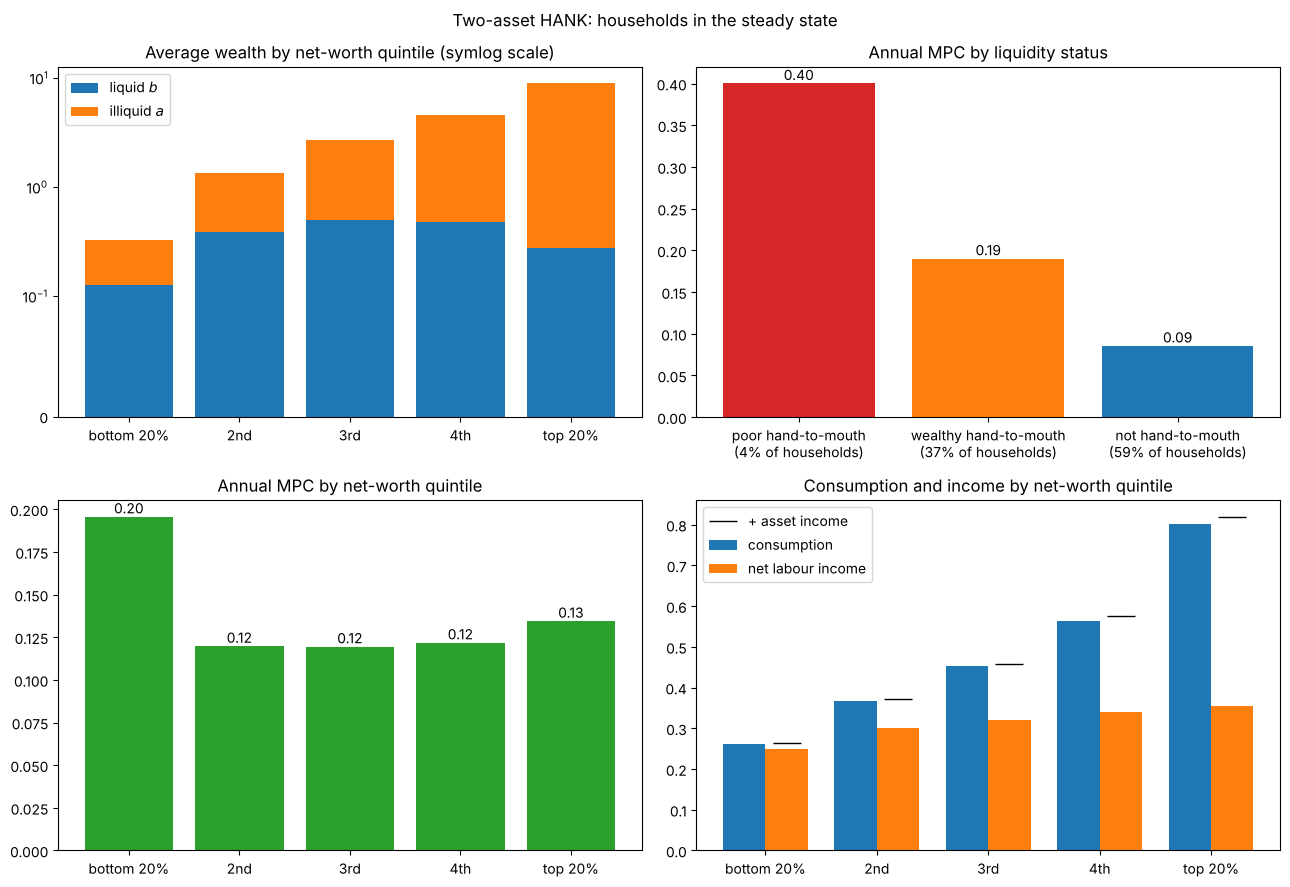

In [13]:
grp = make_groups(M)
(W_q, labels_q), (W_h, labels_h) = grp['quintile'], grp['liquidity']
prof_q, prof_h = steady_state_profile(M, W_q), steady_state_profile(M, W_h)

print(f'mean annual net labour income = {grp["mean_income"]:.3f} (wealth and income below are in the same units)\n')
print(f'{"":12s}{"liquid":>8s}{"illiquid":>10s}{"consumption":>13s}{"labour inc.":>13s}{"asset inc.":>12s}{"MPC":>7s}')
for j, lab in enumerate(labels_q):
    print(f'{lab:12s}' + ''.join(f'{prof_q[k][j]:{w}.3f}' for k, w in
                                 (('liquid', 8), ('illiquid', 10), ('consumption', 13), ('labour income', 13),
                                  ('asset income', 12), ('MPC', 7))))
print()
for j, lab in enumerate(labels_h):
    print(f'{lab:24s} {100 * prof_h["mass"][j]:3.0f}% of households, MPC {prof_h["MPC"][j]:.2f}')

plot_steady_state(prof_q, labels_q, prof_h, labels_h)

**Wealth rises steeply across quintiles, and almost all of it is illiquid.** The bottom fifth holds about 0.3 in total, roughly one year of mean net labour income (0.31). The top fifth holds about 8.9, almost 30 years' worth, nearly all of it in the illiquid fund. Liquid wealth peaks in the middle quintiles: the richest households keep relatively little cash, because the liquidity premium makes deposits a poor investment for anyone who can afford to wait.

**MPCs follow liquidity.** The poor hand-to-mouth spend about 40 cents of each extra dollar within the year, the wealthy hand-to-mouth about 19 cents, and everyone else about 9 cents. By quintile, only the bottom fifth stands out, with an MPC of 0.20. The top fifth's MPC (0.13) is barely below the middle quintiles', even though two-thirds of top-fifth households end the period with no liquid wealth. So holding no liquid wealth is a weak guide to spending behaviour in this calibration. The next section explains why.

**Consumption is financed differently across the distribution.** Net labour income varies relatively little across quintiles, because productivity is mean-reverting. Consumption rises steeply with wealth, and the top fifth consumes more than twice its labour income, financing the gap with asset income.

The average annual MPC in this calibration is low (0.14) compared with empirical estimates, so the effect sizes below are illustrative. The pattern — income gains for the asset-poor, revaluation losses for the asset-rich — should survive recalibration.

#### Why MPCs differ

The MPC is the slope of a household's **consumption function**: how consumption changes with cash on hand, this year's income plus liquid savings. So the question is why that function is steeper for some households than others.

Diminishing marginal utility on its own doesn't produce different slopes. With no income risk and no borrowing limit, a household with the same CRRA preferences would have a straight-line consumption function. It would spend the same small fraction of any windfall, roughly the interest on it, whatever its wealth. In this calibration that benchmark MPC is $1 - (\beta_h R_b)^{1/\sigma_c}/R_b \approx 0.055$.

Two features bend the consumption function into a concave shape, so that it is steepest at low cash on hand:

- **The borrowing limit.** A household with no liquid wealth that would like to borrow cannot. Extra cash relaxes that constraint, and much of it is spent.
- **Precautionary saving.** With uninsurable income risk, households hold a buffer against bad draws. The smaller the buffer, the more each extra dollar is worth for protection and for spending. As the buffer grows, the curve straightens towards the benchmark. This needs utility with prudence, which CRRA has, on top of diminishing marginal utility.

Where a household sits on its curve then depends on three features of its situation.

1. **Liquid wealth.** An extra dollar matters most to a household with no cash buffer. It can be spent immediately, rather than saved against future income shocks. The MPC falls as liquid wealth rises.
2. **Current productivity, relative to what the household expects.** Productivity is persistent but mean-reverting. A household in a low state expects its income to rise, so it would like to borrow against that future income, and with no liquid wealth it cannot. Extra cash then goes on consumption. A household in a high state expects its income to fall, so it is saving. If it holds no liquid wealth, it is because it is putting its savings in the fund, not because it is short of cash, and most of an extra dollar is saved.
3. **Illiquid wealth, and how costly it is to reach.** The adjustment cost depends on the amount moved *relative to the size of the account*. Taking a given sum out of a large account is cheap, so for a household with a large fund, illiquid wealth works partly like a cash buffer.

The top panels below plot the consumption functions: consumption against liquid cash on hand, $z + (1 + r_b)\, b$. The left panel shows each productivity state, with illiquid wealth of about two years' income. The right panel shows different illiquid holdings at median productivity. Dots mark households at the liquid borrowing limit. The bottom panels plot each curve's slope, the MPC, against the benchmark line. A second chart shows the cost of withdrawing a tenth of a year's income from accounts of different sizes.

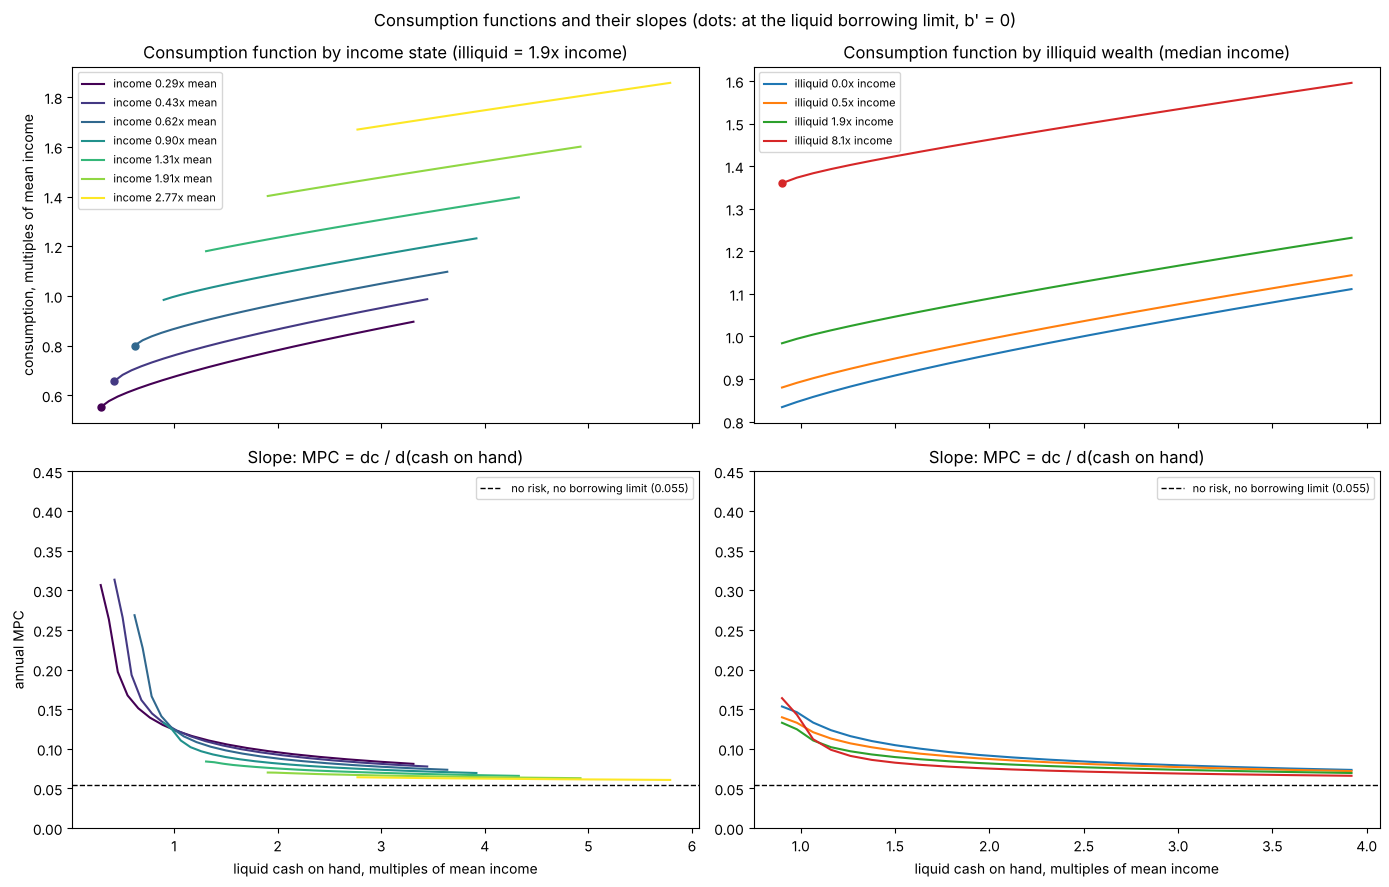

income 0.29x mean: MPC with no cash 0.307, with 1 year of income in cash 0.111, with 3 years 0.081
income 0.90x mean: MPC with no cash 0.133, with 1 year of income in cash 0.082, with 3 years 0.070
income 2.77x mean: MPC with no cash 0.064, with 1 year of income in cash 0.063, with 3 years 0.061


In [14]:
P_h = hh['P']
bg, ag = np.asarray(P_h.b_grid), np.asarray(P_h.a_grid)
z_states = np.asarray(P_h.z)
mean_inc = grp['mean_income']
R_b = 1 + ss['rb']
mpc_benchmark = 1 - (s.beta_h * R_b) ** (1 / s.sigma_c) / R_b       # no income risk, no borrowing limit
b_show = bg <= 3 * mean_inc
mid = len(z_states) // 2
at_limit = hh['b'] <= bg[0] + 1e-10


def policy_and_slope(iz, ja):
    # consumption against liquid cash on hand z + (1 + r_b) b, and its slope (the MPC)
    cash = z_states[iz] + R_b * bg
    return cash, hh['c'][iz, :, ja], np.gradient(hh['c'][iz, :, ja], cash)


fig, ax = plt.subplots(2, 2, figsize=(14, 9), sharex='col')
ja2 = np.argmin(np.abs(ag - 2 * mean_inc))
cmap = plt.get_cmap('viridis')
for iz in range(len(z_states)):
    col = cmap(iz / (len(z_states) - 1))
    cash, cons, slope = policy_and_slope(iz, ja2)
    lim = at_limit[iz, :, ja2] & b_show
    ax[0, 0].plot(cash[b_show] / mean_inc, cons[b_show] / mean_inc, color=col,
                  label=f'income {z_states[iz] / mean_inc:.2f}x mean')
    ax[0, 0].plot(cash[lim] / mean_inc, cons[lim] / mean_inc, 'o', color=col, ms=5)
    ax[1, 0].plot(cash[b_show] / mean_inc, slope[b_show], color=col)
ax[0, 0].set(title=f'Consumption function by income state (illiquid = {ag[ja2] / mean_inc:.1f}x income)',
             ylabel='consumption, multiples of mean income')
ax[0, 0].legend(fontsize=8)

for a_mult, col in zip((0.0, 0.5, 2.0, 8.0), ('C0', 'C1', 'C2', 'C3')):
    ja = np.argmin(np.abs(ag - a_mult * mean_inc))
    cash, cons, slope = policy_and_slope(mid, ja)
    lim = at_limit[mid, :, ja] & b_show
    ax[0, 1].plot(cash[b_show] / mean_inc, cons[b_show] / mean_inc, color=col,
                  label=f'illiquid {ag[ja] / mean_inc:.1f}x income')
    ax[0, 1].plot(cash[lim] / mean_inc, cons[lim] / mean_inc, 'o', color=col, ms=5)
    ax[1, 1].plot(cash[b_show] / mean_inc, slope[b_show], color=col)
ax[0, 1].set(title='Consumption function by illiquid wealth (median income)')
ax[0, 1].legend(fontsize=8)

for a_ in ax[1]:
    a_.axhline(mpc_benchmark, color='k', ls='--', lw=1, label=f'no risk, no borrowing limit ({mpc_benchmark:.3f})')
    a_.set(xlabel='liquid cash on hand, multiples of mean income', ylim=(0, 0.45))
    a_.legend(fontsize=8)
ax[1, 0].set(title='Slope: MPC = dc / d(cash on hand)', ylabel='annual MPC')
ax[1, 1].set(title='Slope: MPC = dc / d(cash on hand)')
fig.suptitle("Consumption functions and their slopes (dots: at the liquid borrowing limit, b' = 0)")
plt.tight_layout()
plt.show()

for iz in (0, mid, len(z_states) - 1):
    cash, cons, slope = policy_and_slope(iz, ja2)
    print(f'income {z_states[iz] / mean_inc:.2f}x mean: MPC with no cash {slope[0]:.3f}, '
          f'with 1 year of income in cash {slope[np.argmin(np.abs(bg - mean_inc))]:.3f}, '
          f'with 3 years {slope[np.argmin(np.abs(bg - 3 * mean_inc))]:.3f}')

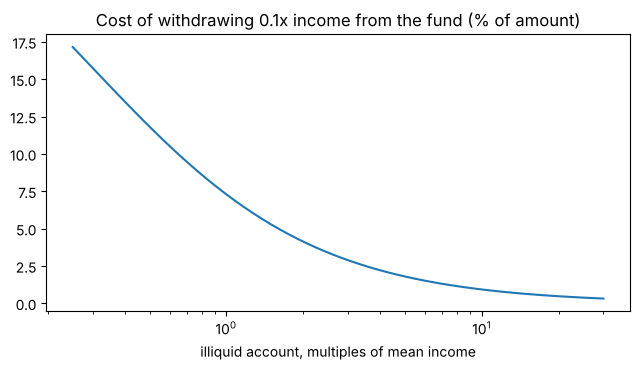

                          mean productivity  in bottom 3 states  illiquid (x income)   MPC
poor hand-to-mouth                     0.52                100%                  0.3  0.40
wealthy hand-to-mouth                  0.76                 54%                 16.7  0.19
not hand-to-mouth                      1.19                 17%                  6.9  0.09


In [15]:
sizes = np.geomspace(0.25, 30, 60)
cost = []
for m in sizes:
    a0 = m * mean_inc
    ap = (1 + ss['ra']) * a0 - 0.1 * mean_inc
    cost.append(float(Psi_and_derivs(jnp.asarray(ap), jnp.asarray(a0), ss['ra'], P_h.chi0, P_h.chi1, P_h.chi2)[0]))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(sizes, 100 * np.array(cost) / (0.1 * mean_inc))
ax.set_xscale('log')
ax.set(title='Cost of withdrawing 0.1x income from the fund (% of amount)',
       xlabel='illiquid account, multiples of mean income')
plt.tight_layout()
plt.show()

print(f'{"":24s}{"mean productivity":>19s}{"in bottom 3 states":>20s}{"illiquid (x income)":>21s}{"MPC":>6s}')
for j, lab in enumerate(labels_h):
    share_low = np.sum(hh['D'] * W_h[j], axis=(1, 2))[:3].sum() / np.sum(hh['D'] * W_h[j])
    print(f'{lab:24s}{prof_h["productivity"][j]:19.2f}{100 * share_low:19.0f}%{prof_h["illiquid"][j] / mean_inc:21.1f}'
          f'{prof_h["MPC"][j]:6.2f}')

**The consumption functions are concave, and steepest at the bottom.** For the lowest income state, the MPC is about 0.31 with no cash, about 0.11 with a year's income in cash, and about 0.08 with three years'. Every curve flattens towards the benchmark line as cash grows: a household with a large enough buffer behaves almost like a textbook permanent-income consumer.

**Productivity decides where a household starts on its curve.** Each curve begins where cash on hand equals that year's income, with no savings. Low-income households start on the steep part, and with no cash their MPC is about 0.3. High-income households start well to the right, where the curve is almost straight, and their MPC is about 0.06 whatever their cash. Only low-income households with no cash are at the borrowing limit.

**Illiquid wealth shifts the level more than the slope.** More wealth in the fund raises consumption at every level of cash but flattens the curve only a little. Part of the reason is that the cost of reaching the fund falls steeply with account size: about 12% of the amount withdrawn from an account worth half a year's income, under 1% from the accounts typical of the top fifth.

That explains the three groups:

- **Poor hand-to-mouth** households are all in the lowest three productivity states and have almost nothing in the fund. Their income is low and expected to rise, and they have nothing to draw on, so their MPC is the highest, about 0.40.
- **Wealthy hand-to-mouth** households are mostly low-productivity too, but they hold about 17 years of income in the fund. They are households whose income has fallen and who have used up their cash, but who can draw on a large account fairly cheaply. Their MPC, about 0.19, is half that of the poor hand-to-mouth.
- **Not hand-to-mouth** households are mostly in high productivity states, with cash. Many are saving out of a temporarily high income, so their MPC is the lowest, about 0.09.

By quintile, the bottom fifth combines low productivity with little of either asset, so its MPC stands out. Higher quintiles have higher productivity on average and large accounts that are cheap to draw on, so their MPCs are similar to each other despite their large shares with no liquid wealth.

#### What moves the curves in the calibration

The table below re-solves only the household problem, with each parameter changed and prices and the discount factor held fixed. Because nothing is recalibrated, households' asset holdings drift away from their targets, shown in the last two columns. A proper exercise would recalibrate $\beta_h$ and the liquidity premium each time, so read these as directions, not sizes.

In [16]:
def household_variant(**changes):
    P2 = hh['P']._replace(**changes)
    pol = solve_policies(P2)
    D2, _, _ = stationary_distribution(P2, pol['a'], pol['b'])
    out = {k: np.asarray(v) for k, v in pol.items()}
    out.update(P=P2, pi_e=hh['pi_e'], D=np.asarray(D2))
    m = mpc_stats(out)
    return (m['mpc'], m['share_constrained'], float(np.sum(out['D'] * out['b']) / ss['B']),
            float(np.sum(out['D'] * out['a']) / ss['k']))


P_h, premium_ss = hh['P'], ss['ra'] - ss['rb']
variants = [('baseline', {}),
            ('adjustment cost chi1 x 2', dict(chi1=2 * P_h.chi1)),
            ('adjustment cost chi1 / 2', dict(chi1=P_h.chi1 / 2)),
            ('small-account term chi0 x 5', dict(chi0=5 * P_h.chi0)),
            ('liquidity premium x 2', dict(rb=ss['ra'] - 2 * premium_ss)),
            ('no liquidity premium', dict(rb=ss['ra'] - 1e-5))]
print(f'{"":30s}{"mean MPC":>9s}{"no cash":>9s}{"liquid / target":>17s}{"illiquid / target":>19s}')
for name, ch in variants:
    mpc_v, constrained_v, B_ratio, A_ratio = household_variant(**ch)
    print(f'{name:30s}{mpc_v:9.3f}{100 * constrained_v:8.0f}%{B_ratio:17.2f}{A_ratio:19.2f}')

                               mean MPC  no cash  liquid / target  illiquid / target


baseline                          0.138      41%             1.00               1.00


adjustment cost chi1 x 2          0.215      73%             0.33               3.94


adjustment cost chi1 / 2          0.123      45%             0.71               0.79


small-account term chi0 x 5       0.132      40%             0.93               0.91


liquidity premium x 2             0.161      55%             0.49               1.09


no liquidity premium              0.093       6%             6.06               0.07


- **The adjustment-cost scale $\chi_1$** is the main lever. Doubling it makes the fund harder to reach, so more households end up with no cash, and the average MPC rises from about 0.14 to over 0.2. Halving it lowers the MPC.
- **The small-account term $\chi_0$** makes withdrawals from small accounts cheaper. Raising it lowers MPCs slightly.
- **The liquidity premium** is the cost of holding cash instead of fund units. Doubling it pushes more households to hold no cash and raises the MPC. Removing it removes any reason to hold the illiquid asset at all: almost nobody holds the fund, households keep large cash buffers, and the model becomes a one-asset economy with an MPC below 0.1.
- **The income process** works through the productivity channel above: how far and how persistently income falls in bad states determines how many households want to borrow and cannot. We don't vary it here.

To get closer to empirical MPCs, the usual route is a larger adjustment cost, often with a fixed or kinked component as in Kaplan, Moll and Violante, together with recalibrating $\beta_h$ and the premium to keep asset holdings at their targets.

### The cost of each approach

Here is the timing behind the change of method.

In [17]:
x0 = jnp.asarray(M['x_ss'])
zeros, eps0 = jnp.zeros(s.T + 1), jnp.full(s.T + 1, s.eps)
F_ss = jax.jit(lambda x: M['resid'](x, zeros, zeros, eps0))
F_ss(x0).block_until_ready()                                   # compile
t0 = time.time()
for _ in range(3):
    F_ss(x0).block_until_ready()
t_eval = (time.time() - t0) / 3

hb = make_household_block(s, hh)
t0 = time.time()
_ = household_jacobian(s, hh, hb)
t_fake = time.time() - t0

n_unknowns = len(M['x_ss'])
print(f'one evaluation of the nonlinear model: {t_eval:.2f}s')
print(f'exact Jacobian by forward mode: ~{n_unknowns} passes x ~2 evaluations = ~{2 * n_unknowns * t_eval / 60:.0f} minutes, every Newton step')
print(f'household Jacobian by the fake-news algorithm: {t_fake:.0f}s, once')

one evaluation of the nonlinear model: 1.49s
exact Jacobian by forward mode: ~1054 passes x ~2 evaluations = ~52 minutes, every Newton step
household Jacobian by the fake-news algorithm: 16s, once


On this machine, one exact Jacobian would take close to an hour, and the old method needed one for every Newton step. The fake-news algorithm gets everything we need in about 20 seconds, once.

## A monetary policy shock

We apply the same shock as in the earlier lectures, a cut of 100 basis points in the rule's intercept decaying at rate $0.7$, $\nu_t = -0.01 \times 0.7^t$. The iteration log shows the quasi-Newton method at work.

In [18]:
t = np.arange(s.T + 1)
nu = -0.01 * 0.7 ** t

t0 = time.time()
e = solve(M, nu=nu)
print(f'\nsolved in {time.time() - t0:.0f}s, {e["iterations"]} iterations')
print(f'max |residual| = {e["residual"]:.1e},  asset market (Walras) = {np.max(np.abs(e["asset_mkt"][:-1])):.1e}')

   quasi-Newton iteration 0: max |residual| = 1.000e-02


   quasi-Newton iteration 1: max |residual| = 4.315e-03


   quasi-Newton iteration 2: max |residual| = 1.433e-03


   quasi-Newton iteration 3: max |residual| = 3.864e-04


   quasi-Newton iteration 4: max |residual| = 1.026e-04


...

   quasi-Newton iteration 11: max |residual| = 2.605e-09


   quasi-Newton iteration 12: max |residual| = 5.536e-10


   quasi-Newton iteration 13: max |residual| = 1.176e-10


   quasi-Newton iteration 14: max |residual| = 2.498e-11



solved in 29s, 14 iterations
max |residual| = 2.5e-11,  asset market (Walras) = 1.7e-07


The residual falls by roughly a factor of four each iteration: linear convergence, as expected with a fixed Jacobian, rather than the quadratic convergence of full Newton. Each iteration costs one model evaluation and one back-substitution, so the whole solve takes well under a minute.

The asset market, which is not part of the system, clears to within about $10^{-7}$ of the capital stock. It isn't exact to machine precision, as in earlier lectures, most likely because of truncation at the top of the asset grids, where the lottery cannot place households exactly on their chosen wealth.

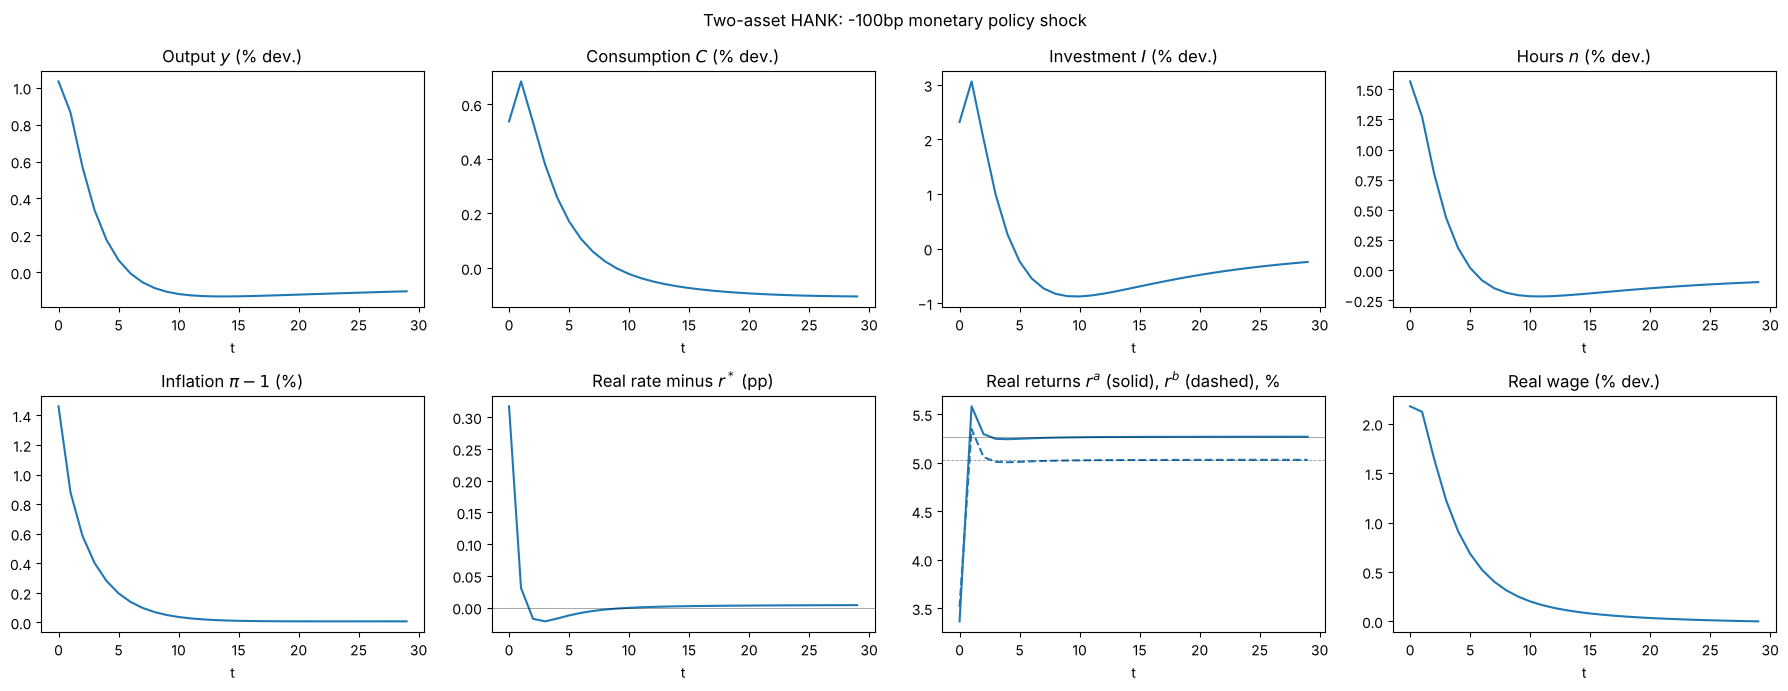

In [19]:
def plot_hank(econs, labels, M, t_max=30, title=None):
    s, ss, hh = M['s'], M['ss'], M['hh']
    r_star = 1 / s.beta - 1
    pct = lambda key, ref: (lambda e: 100 * (e[key] / ref - 1))
    series = [('Output $y$ (% dev.)', pct('y', ss['y'])), ('Consumption $C$ (% dev.)', pct('C', hh['Y_ss'][2])),
              ('Investment $I$ (% dev.)', pct('I', s.delta * s.k_ss)), ('Hours $n$ (% dev.)', pct('n', s.n_ss)),
              (r'Inflation $\pi - 1$ (%)', lambda e: 100 * (e['pi'] - 1)),
              ('Real rate minus $r^*$ (pp)', lambda e: 100 * (e['r_real'] - r_star)),
              ('Real returns $r^a$ (solid), $r^b$ (dashed), %', None),
              ('Real wage (% dev.)', pct('real_w', ss['w']))]
    fig, ax = plt.subplots(2, 4, figsize=(18, 7))
    for a_, (ttl, fn) in zip(ax.flat, series):
        for e, lab in zip(econs, labels):
            if fn is None:
                ln, = a_.plot(100 * e['ra'][:t_max], label=lab)
                a_.plot(100 * e['rb'][:t_max], ls='--', color=ln.get_color())
                a_.axhline(100 * ss['ra'], color='k', lw=0.6, alpha=0.4)
                a_.axhline(100 * ss['rb'], color='k', lw=0.6, alpha=0.4, ls='--')
            else:
                a_.plot(fn(e)[:t_max], label=lab)
        a_.set_title(ttl)
        a_.set_xlabel('t')
    ax.flat[5].axhline(0, color='k', lw=0.6, alpha=0.4)
    if len(econs) > 1:
        ax.flat[0].legend()
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_hank([e], ['HANK'], M, title='Two-asset HANK: -100bp monetary policy shock')

In [20]:
r_star = 1 / s.beta - 1
Css = hh['Y_ss'][2]
print('impact responses (t = 0)')
print(f'  output {100 * (e["y"][0] / ss["y"] - 1):+.2f}%, consumption {100 * (e["C"][0] / Css - 1):+.2f}%, '
      f'investment {100 * (e["I"][0] / (s.delta * s.k_ss) - 1):+.2f}%, hours {100 * (e["n"][0] / s.n_ss - 1):+.2f}%')
print(f'  inflation {100 * (e["pi"][0] - 1):.2f}%, nominal rate {100 * (e["i"][0] - r_star):+.2f}pp vs r*, '
      f'real rate {100 * (e["r_real"][0] - r_star):+.2f}pp vs r* (cumulative {100 * np.sum(e["r_real"] - r_star):+.2f}pp)')
print(f'  real wage {100 * (e["real_w"][0] / ss["w"] - 1):+.2f}%, real dividends {100 * (e["d"][0] / e["p"][0] / ss["d"] - 1):+.2f}%, '
      f'real firm value {100 * (e["v"][0] / s.k_ss - 1):+.2f}%, real government debt {100 * (e["b"][0] / s.b_ss - 1):+.2f}%')
print(f'  real returns at t = 0: r_a {100 * e["ra"][0]:.2f}%, r_b {100 * e["rb"][0]:.2f}%   '
      f'(steady state {100 * ss["ra"]:.2f}%, {100 * ss["rb"]:.2f}%);  at t = 1: {100 * e["ra"][1]:.2f}%, {100 * e["rb"][1]:.2f}%')

impact responses (t = 0)
  output +1.03%, consumption +0.54%, investment +2.32%, hours +1.56%
  inflation 1.46%, nominal rate +1.24pp vs r*, real rate +0.32pp vs r* (cumulative +0.51pp)
  real wage +2.18%, real dividends -9.39%, real firm value -1.40%, real government debt -1.51%
  real returns at t = 0: r_a 3.36%, r_b 3.51%   (steady state 5.26%, 5.03%);  at t = 1: 5.58%, 5.34%


### How the shock works

The aggregate story is familiar from the earlier lectures. The cut in the rule's intercept sets off a boom. Inflation rises about 1.5% on impact, and because $\phi_\pi = 1.5$ the rule responds by **raising** the nominal rate, by about 1.2pp. The real rate is about 0.3pp above $r^*$ on impact, roughly neutral or slightly below it for the next several years, and a fraction of a basis point above it for a long time after that, so cumulatively policy is somewhat tight in real terms. Firms meet higher demand by producing more, marginal cost rises, and the real wage rises by over 2% while real dividends fall by over 9%.

What is new is what happens to households' **assets** when the shock hits:

- **Deposits lose value.** Liquid deposits are nominal, so the surprise jump in prices at $t = 0$ erodes them. The real return on deposits in the first period is about 3.5%, against 5.0% in steady state, and real government debt falls by about 1.5%. That is a transfer from deposit holders to the government.
- **Equity loses value.** Lower profits, discounted at higher interest rates, reduce the firm's value by about 1.4% on impact. The illiquid fund's first-period real return falls to about 3.4%, against 5.3% in steady state.
- **Returns then rise, briefly.** In the second period both assets earn **more** than in steady state, reflecting the high real rate set at $t = 0$. After that, returns settle back to their steady-state levels.

### Where the consumption response comes from

Because the household block is a function of four input paths, we can split the consumption response into the part due to each input, using the household Jacobian:

$$
\Delta C_t \approx \sum_{k \in \{r^a,\, r^b,\, \zeta,\, \beta\}} \sum_s \mathcal{J}^{C,k}_{t,s}\, \Delta X^k_s
$$

The returns $r^a$ and $r^b$ are the **direct** effects of monetary policy on households. Net income $\zeta$ and the hours-driven discount factor $\beta$ are the **indirect** effects, which come from what policy does to the labour market.

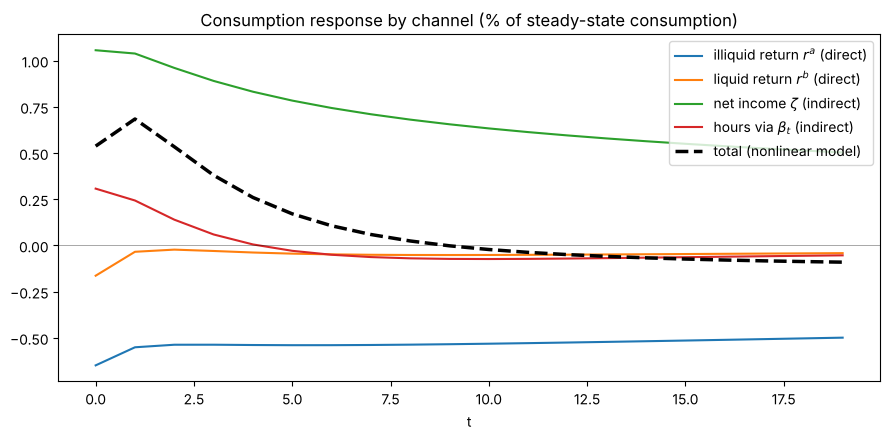

consumption response at t = 0, % of steady-state consumption
  ra                 -0.65
  rb                 -0.16
  zeta               +1.06
  beta               +0.31
  total (nonlinear)  +0.54
  total (linear)     +0.55


In [21]:
parts = consumption_decomposition(M, e)
names = {'ra': 'illiquid return $r^a$ (direct)', 'rb': 'liquid return $r^b$ (direct)',
         'zeta': r'net income $\zeta$ (indirect)', 'beta': r'hours via $\beta_t$ (indirect)',
         'total (nonlinear)': 'total (nonlinear model)'}
fig, ax = plt.subplots(figsize=(9, 4.5))
for key, lab in names.items():
    ls = '-' if key != 'total (nonlinear)' else '--'
    lw = 1.5 if key != 'total (nonlinear)' else 2.5
    ax.plot(100 * parts[key][:20] / Css, ls=ls, lw=lw, label=lab, color='k' if key.startswith('total') else None)
ax.axhline(0, color='k', lw=0.6, alpha=0.4)
ax.set(title='Consumption response by channel (% of steady-state consumption)', xlabel='t')
ax.legend()
plt.tight_layout()
plt.show()

print('consumption response at t = 0, % of steady-state consumption')
for key, lab in names.items():
    print(f'  {key:18s} {100 * parts[key][0] / Css:+.2f}')
print(f'  {"total (linear)":18s} {100 * parts["total (linear)"][0] / Css:+.2f}')

**The direct effects are negative.** On impact, the illiquid-return channel lowers consumption by about 0.65% and the liquid-return channel by about 0.16%. Both come mainly from the capital losses at $t = 0$, with a small contribution from the higher returns in the second period. The losses are large relative to consumption, because the illiquid fund holds the whole capital stock: a fall of almost two percentage points in its first-period return is a loss of over a tenth of a year's consumption. Households spread that loss over many years, so the illiquid channel stays close to $-0.5\%$ for decades of model time.

**The indirect effects carry the whole response.** Higher net income adds about 1.06%, and the hours effect on the discount factor about 0.31%. Consumption rises about 0.54% on impact only because incomes rise by enough to more than offset the direct channels. The income channel is also persistent, for the mirror-image reason: households save part of the extra income, which raises their wealth and their consumption for years.

**The two wealth effects nearly cancel in the long run.** Once the boom fades, after about nine periods, the lasting wealth loss slightly outweighs the lasting gain from saved income. Consumption, and with it hours and output, dip slightly below steady state for a long time. This tail would not appear in a representative-agent model, where the capital loss on the firm is a loss to the same household that owns the firm's future profits.

This is the HANK message in its starkest form. Kaplan, Moll and Violante (2018) find that in a HANK economy the direct effect of a rate cut accounts for only around a fifth of the consumption response. Their experiment lowers the real interest rate, so the direct effect is small but positive. Here, as in the earlier lectures, the rule's response to inflation means the real rate actually rises, and the surprise inflation imposes capital losses. So the direct effect works **against** the expansion, and the income channel does all the work.

The linear decomposition is close to the nonlinear total, so the Jacobian-based split is reliable for a shock of this size.

### Who gains and who loses

To follow each group through the transition, we take the households in it at $t = 0$, and move them forward in two ways: with the policies households choose along the equilibrium path, and with the steady-state policies, which give the group's **no-shock path**.

The second path matters because group members mix over time even without a shock. Productivity mean-reverts and savings accumulate, so the bottom quintile gets richer on average and the top quintile poorer. Measuring a group's response against its steady-state level would mix that drift into the response, so each group is measured against **its own no-shock path**.

Each group's **contribution** to the aggregate response is the change in its total consumption relative to aggregate steady-state consumption. The contributions must add up exactly to the aggregate consumption response from the solver, which is a built-in check.

In [22]:
def group_paths(M, econ, W):
    # Consumption, liquid and illiquid holdings of each group along the transition and the no-shock path.
    s, hh, hb = M['s'], M['hh'], M['hb']
    Th = s.T + 1
    back = jax.jit(hb['backward'])
    fwd = jax.vmap(hb['forward_step'], in_axes=(0, None, None))
    Dg0 = jnp.asarray(hh['D'][None] * W)

    @jax.jit
    def follow(a, b, c):
        def step(Dg, pol):
            a_t, b_t, c_t = pol
            out = jnp.stack([jnp.sum(Dg * c_t, axis=(1, 2, 3)), jnp.sum(Dg * b_t, axis=(1, 2, 3)),
                             jnp.sum(Dg * a_t, axis=(1, 2, 3))])
            return fwd(Dg, a_t, b_t), out
        _, out = jax.lax.scan(step, Dg0, (a, b, c))
        return out                                                        # (Th, 3, G)

    shocked = back(*[jnp.asarray(econ[k]) for k in ('ra', 'rb', 'zeta', 'beta_t')])
    base = back(*[jnp.full(Th, v) for v in hh['inputs_ss']])
    o1 = np.asarray(follow(shocked[0], shocked[1], shocked[2]))
    o0 = np.asarray(follow(base[0], base[1], base[2]))
    mass = np.array([np.sum(hh['D'] * Wg) for Wg in W])
    C1, C0 = o1[:, 0, :], o0[:, 0, :]
    return dict(C=C1, C_base=C0, dev=C1 / C0 - 1, contribution=(C1 - C0) / hh['Y_ss'][2],
                B=o1[:, 1, :] / mass, A=o1[:, 2, :] / mass, mass=mass)


def impact_income(M, econ, W):
    # Change in each group's resources at t = 0, relative to its steady-state consumption: labour income vs
    # returns on assets (the date-0 revaluation), per household in the group.
    hh = M['hh']
    P = hh['P']
    bg, ag = np.asarray(P.b_grid), np.asarray(P.a_grid)
    D = hh['D']
    e3 = np.asarray(P.e_grid)[:, None, None]
    ra_ss, rb_ss, zeta_ss = hh['inputs_ss'][:3]
    d_labour = (econ['zeta'][0] - zeta_ss) * e3
    d_assets = (econ['ra'][0] - ra_ss) * ag[None, None, :] + (econ['rb'][0] - rb_ss) * bg[None, :, None]
    out = {}
    for name, x in (('labour income', d_labour), ('asset returns', d_assets)):
        out[name] = np.array([np.sum(D * Wg * np.broadcast_to(x, D.shape)) / np.sum(D * Wg * hh['c']) for Wg in W])
    return out




def plot_responses(paths_q, labels_q, paths_h, labels_h, imp_q, agg_dev, t_max=20, title='', save=None):
    fig, ax = plt.subplots(2, 2, figsize=(13, 9))
    for g, lab in enumerate(labels_q):
        ax[0, 0].plot(100 * paths_q['dev'][:t_max, g], label=lab)
    ax[0, 0].plot(100 * agg_dev[:t_max], 'k--', label='aggregate')
    ax[0, 0].set_title('Consumption response by net-worth quintile (% vs own no-shock path)')
    ax[0, 0].legend()
    for g, lab in enumerate(labels_h):
        ax[0, 1].plot(100 * paths_h['dev'][:t_max, g], label=f'{lab} ({100 * paths_h["mass"][g]:.0f}%)')
    ax[0, 1].plot(100 * agg_dev[:t_max], 'k--', label='aggregate')
    ax[0, 1].set_title('Consumption response by liquidity status (%)')
    ax[0, 1].legend()
    pos, neg = np.zeros(t_max), np.zeros(t_max)                        # stack positives up, negatives down
    for g, lab in enumerate(labels_q):
        contrib = 100 * paths_q['contribution'][:t_max, g]
        base = np.where(contrib >= 0, pos, neg)
        ax[1, 0].bar(np.arange(t_max), contrib, bottom=base, label=lab)
        pos, neg = pos + np.maximum(contrib, 0), neg + np.minimum(contrib, 0)
    ax[1, 0].plot(100 * agg_dev[:t_max], 'k--', label='aggregate')
    ax[1, 0].set_title('Contributions to the aggregate consumption response (pp)')
    ax[1, 0].legend(fontsize=8)
    x = np.arange(len(labels_q))
    width = 0.38
    ax[1, 1].bar(x - width / 2, 100 * imp_q['labour income'], width, label='labour income')
    ax[1, 1].bar(x + width / 2, 100 * imp_q['asset returns'], width, label='asset returns (revaluation)')
    ax[1, 1].axhline(0, color='k', lw=0.8)
    ax[1, 1].set_xticks(x)
    ax[1, 1].set_xticklabels(labels_q)
    ax[1, 1].set_title('Change in resources at t = 0 (% of own consumption)')
    ax[1, 1].legend()
    for a_ in ax.flat[:3]:
        a_.set_xlabel('t')
    fig.suptitle(title)
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=110)
    plt.show()

checks
  quintile masses: [0.2 0.2 0.2 0.2 0.2]
  quintile contributions vs aggregate (from the group paths): 5.9e-12
  liquidity-group contributions vs quintile contributions: 7.6e-14
  aggregate vs general-equilibrium solution: 3.3e-09

consumption response (%)        t=0    t=5   t=10   t=19  contrib. t=0 (pp)
bottom 20%                     2.25   1.21   0.68   0.35              0.240
2nd                            1.09   0.71   0.48   0.35              0.163
3rd                            0.66   0.33   0.16   0.11              0.121
4th                            0.30   0.02  -0.13  -0.16              0.070
top 20%                       -0.17  -0.43  -0.55  -0.55             -0.057
poor hand-to-mouth             4.51   1.11   0.31   0.04              0.072
wealthy hand-to-mouth          0.12  -0.28  -0.43  -0.43              0.051
not hand-to-mouth              0.72   0.47   0.26   0.15              0.415
aggregate                      0.54   0.17  -0.02  -0.09

change in resources

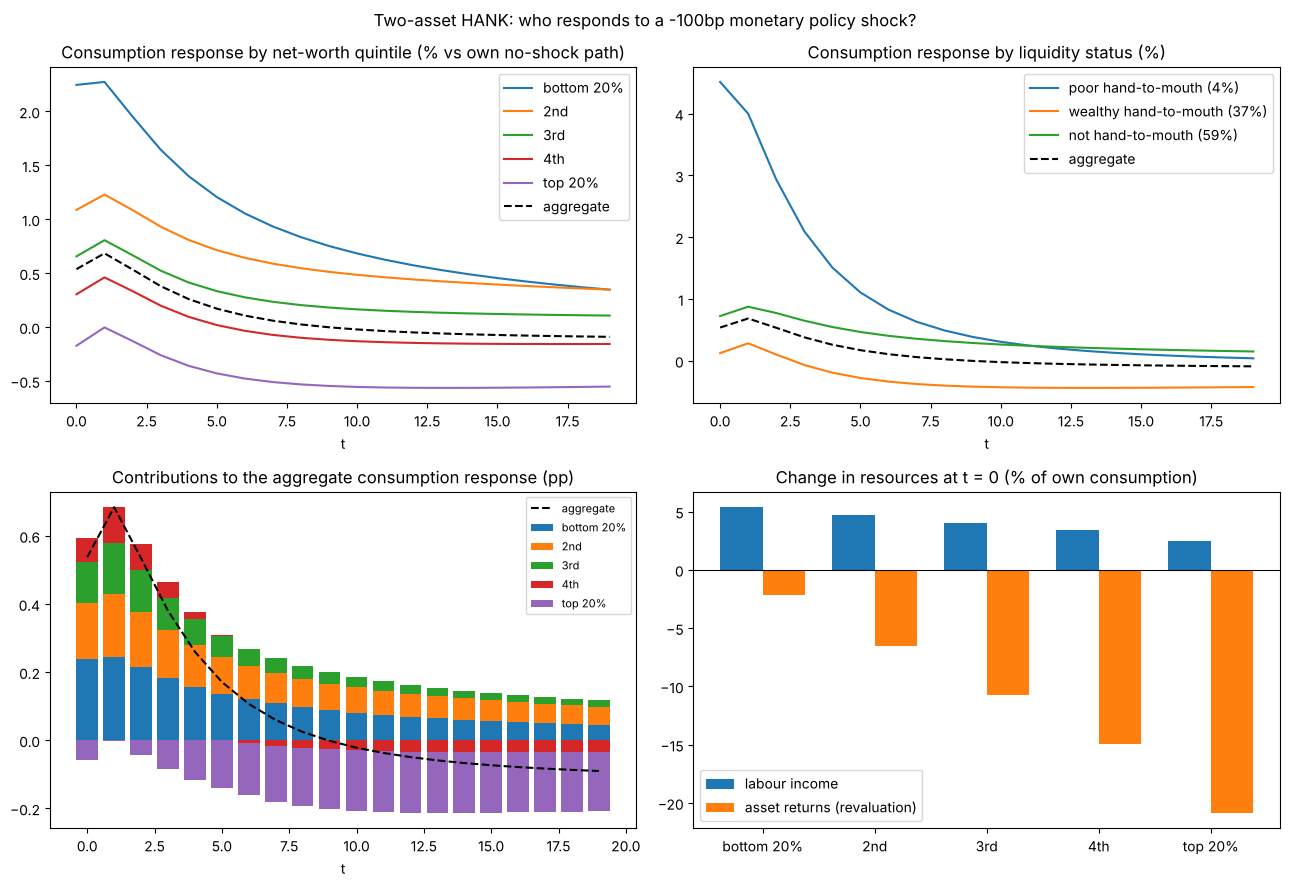

In [23]:
paths_q, paths_h = group_paths(M, e, W_q), group_paths(M, e, W_h)
imp_q = impact_income(M, e, W_q)
agg_dev = paths_q['contribution'].sum(axis=1)

print('checks')
print(f'  quintile masses: {np.round(paths_q["mass"], 6)}')
print(f'  quintile contributions vs aggregate (from the group paths): '
      f'{np.max(np.abs(agg_dev - (e["C"] - paths_q["C_base"].sum(axis=1)) / Css)):.1e}')
print(f'  liquidity-group contributions vs quintile contributions: '
      f'{np.max(np.abs(paths_h["contribution"].sum(axis=1) - agg_dev)):.1e}')
print(f'  aggregate vs general-equilibrium solution: {np.max(np.abs(agg_dev - (e["C"] / Css - 1))):.1e}\n')

print(f'{"consumption response (%)":28s}{"t=0":>7s}{"t=5":>7s}{"t=10":>7s}{"t=19":>7s}{"contrib. t=0 (pp)":>19s}')
for paths, labels in ((paths_q, labels_q), (paths_h, labels_h)):
    for j, lab in enumerate(labels):
        print(f'{lab:28s}' + ''.join(f'{100 * paths["dev"][tt, j]:7.2f}' for tt in (0, 5, 10, 19))
              + f'{100 * paths["contribution"][0, j]:19.3f}')
print(f'{"aggregate":28s}' + ''.join(f'{100 * agg_dev[tt]:7.2f}' for tt in (0, 5, 10, 19)))
print('\nchange in resources at t = 0 (% of own consumption)')
for j, lab in enumerate(labels_q):
    print(f'  {lab:12s} labour income {100 * imp_q["labour income"][j]:+6.1f}   asset revaluation {100 * imp_q["asset returns"][j]:+6.1f}')

plot_responses(paths_q, labels_q, paths_h, labels_h, imp_q, agg_dev,
               title='Two-asset HANK: who responds to a -100bp monetary policy shock?')

**The headline: the shock raises consumption most for the poorest households and slightly lowers it for the richest.**

- **By quintile.** On impact, consumption rises about 2.2% in the bottom fifth, then progressively less, and falls about 0.2% in the top fifth. The gap then widens. Ten periods on, the bottom fifth is still about 0.7% above its no-shock path, while the top fifth has fallen to about 0.55% below it, and stays there for years.
- **By liquidity status.** The poor hand-to-mouth raise consumption about 4.5% on impact, and the effect fades over the following decade. The wealthy hand-to-mouth barely move at first (+0.1%) and then fall below their no-shock path, to about $-0.4\%$. Households who are not hand-to-mouth gain about 0.7% and stay above their no-shock path for a long time.
- **Contributions.** The bottom fifth accounts for about 0.24pp of the 0.54pp aggregate rise on impact, nearly half, although it does only about a tenth of all consumption. The top fifth subtracts throughout, and by around $t = 10$ its drag roughly offsets everyone else's gains. That is the source of the small, persistent dip in aggregate consumption seen earlier.

**Why: who gains from wages and who loses on assets.** The bottom-right panel shows each quintile's change in resources at $t = 0$, as a share of its own consumption.

- **Labour income** rises for everyone: worth about 5.4% of consumption in the bottom fifth and 2.5% in the top fifth. Labour income is a much larger part of poorer households' resources.
- **Asset revaluation** works the other way. The shock cuts the value of equity, and the surprise inflation cuts the value of nominal deposits. The loss is about 2% of consumption in the bottom fifth and about 21% in the top fifth.

The revaluation losses are large even in the middle quintiles, yet their consumption still rises on impact. The reason is the difference between a one-off change in resources and a lasting one.

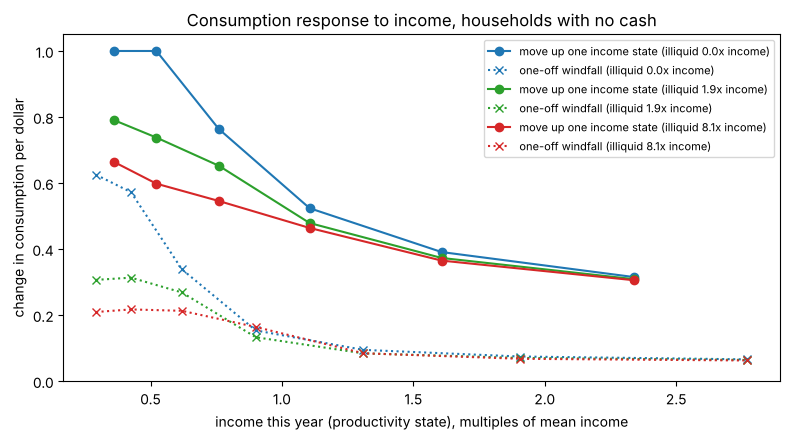

In [24]:
x_inc = z_states / mean_inc
x_mid = 0.5 * (x_inc[1:] + x_inc[:-1])
fig, ax = plt.subplots(figsize=(8, 4.5))
for a_mult, col in zip((0.0, 2.0, 8.0), ('C0', 'C2', 'C3')):
    ja = np.argmin(np.abs(ag - a_mult * mean_inc))
    persistent = np.diff(hh['c'][:, 0, ja]) / np.diff(z_states)
    windfall = np.array([policy_and_slope(iz, ja)[2][0] for iz in range(len(z_states))])
    ax.plot(x_mid, persistent, 'o-', color=col, label=f'move up one income state (illiquid {ag[ja] / mean_inc:.1f}x income)')
    ax.plot(x_inc, windfall, 'x:', color=col, label=f'one-off windfall (illiquid {ag[ja] / mean_inc:.1f}x income)')
ax.set(title='Consumption response to income, households with no cash',
       xlabel='income this year (productivity state), multiples of mean income', ylabel='change in consumption per dollar',
       ylim=(0, 1.05))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The solid lines show how much consumption rises per dollar when a household moves up one income state, which is a **lasting** change, because productivity is persistent. The dotted lines show the one-off windfall MPC at each state. Among low-income households with about two years' income in the fund, moving up a state raises consumption by about 80 cents per dollar of extra income, against about 30 cents for a windfall. A household with nothing in the fund consumes almost all of a lasting rise.

A household that expects to stay richer raises its consumption by most of the increase. A one-off dollar is spread over many years. Income only takes seven values, so the solid lines average over large steps, and their size depends on how persistent productivity is, but the gap is large throughout.

The monetary shock works the same way. The rise in labour income is not permanent, but it lasts several years, so households treat it more like a lasting change and spend a large share of it. The revaluation is a one-off loss of wealth, and households spread it over many years: their MPC out of wealth is low. So the income gain dominates on impact, and the revaluation shows up instead as a small but persistent fall in consumption, concentrated at the top.

That is the redistribution channel the representative-agent and two-agent models cannot show. With one household, or with hand-to-mouth households who own nothing, the losses on assets and the gains in wages fall on the same people, or the asset losses fall on nobody who changes their spending.

**Caveats.** The effect sizes depend on the calibration, whose MPCs are low. The persistence of the top fifth's consumption loss is plausible, given lasting wealth losses, but has not been checked against any benchmark.

### Linear and nonlinear solutions

The first quasi-Newton step from the steady state is the first-order (linear) solution. Comparing it with the converged nonlinear solution shows how much the nonlinearities matter.

In [25]:
lu = jax.scipy.linalg.lu_factor(jnp.asarray(M['J_ge']))
x_lin = jnp.asarray(M['x_ss']) - jax.scipy.linalg.lu_solve(lu, M['resid'](jnp.asarray(M['x_ss']), jnp.asarray(nu), zeros, eps0))
_, e_lin = M['resid'](x_lin, jnp.asarray(nu), zeros, eps0, full=True)
e_lin = {k: np.asarray(v) for k, v in e_lin.items()}

print(f'{"t = 0":28s}{"linear":>10s}{"nonlinear":>11s}')
for lab, fn in [('output (% dev.)', lambda x: 100 * (x['y'][0] / ss['y'] - 1)),
                ('consumption (% dev.)', lambda x: 100 * (x['C'][0] / Css - 1)),
                ('investment (% dev.)', lambda x: 100 * (x['I'][0] / (s.delta * s.k_ss) - 1)),
                ('inflation (%)', lambda x: 100 * (x['pi'][0] - 1))]:
    print(f'  {lab:26s}{fn(e_lin):10.2f}{fn(e):11.2f}')
print(f'\nprice-adjustment cost at t = 0 in the nonlinear solution: {100 * e["pac"][0] / ss["y"]:.2f}% of output '
      f'(zero to first order)')

t = 0                           linear  nonlinear
  output (% dev.)                 0.78       1.03
  consumption (% dev.)            0.58       0.54
  investment (% dev.)             4.48       2.32
  inflation (%)                   1.30       1.46

price-adjustment cost at t = 0 in the nonlinear solution: 0.54% of output (zero to first order)


Consumption and inflation are close in the two solutions, but investment and output are not: investment rises about 4.5% in the linear solution and only about 2.3% in the nonlinear one.

The main source of the difference is the price-adjustment cost. It is quadratic in inflation, so it is zero to first order, and the linear solution ignores it. In the nonlinear solution, with inflation of about 1.5% and $\zeta_p = 50$, firms use up around half a percent of output repricing. Those goods have to come from somewhere: output rises more, but investment is crowded out.

So a linear solution would overstate the investment response here by about a factor of two. This is a good reason to solve the nonlinear model, which the quasi-Newton method does at little extra cost. It is also a caution about Rotemberg pricing: with these parameters, a noticeable share of the measured rise in output is resources spent on changing prices.

## Summary and next steps

Moving from two agents to a continuum of households with two assets changes both the economics and the computation.

**Economics:**
- The hand-to-mouth share is now an outcome: around 40% of households hold no liquid wealth, most of them owning illiquid assets.
- Monetary policy reaches households through their assets as well as their incomes. Surprise inflation erodes deposits, and equity values fall with profits.
- In this experiment the direct channels push consumption down, and the rise in consumption comes entirely through incomes and hours.
- Responses differ sharply across households. The asset-poor gain most from higher wages, while the top fifth by net worth bears large revaluation losses and consumes slightly less for years.

**Computation:**
- The model is still a stacked system of equilibrium conditions over all dates, solved for every path at once.
- What changes is the Jacobian. It is computed once at the steady state, with the fake-news algorithm for the household block and exact differentiation for the rest. A quasi-Newton iteration then solves the fully nonlinear model.

**Natural extensions:**
- **Calibration.** Target higher MPCs, for example with a larger adjustment cost or a lower liquidity premium, and use a consistent annual or quarterly calibration throughout.
- **Fiscal policy.** The model already has a government budget and tax rule, and `solve` accepts paths for government spending. How spending is financed matters in a HANK economy in ways it cannot in the representative-agent models.
- **Labour market.** Restore the output gap in the rule with a definition of potential output suited to a heterogeneous economy, and replace the union placeholder with search and matching, which would make unemployment risk move with the cycle.
- **Larger shocks.** Update the Jacobian along the way (Broyden's method) or scale shocks up in steps.

## References

- Auclert, A., Bardóczy, B., Rognlie, M. and Straub, L. (2021). Using the sequence-space Jacobian to solve and estimate heterogeneous-agent models. *Econometrica*, 89(5), 2375–2408.
- Kaplan, G., Moll, B. and Violante, G. L. (2018). Monetary policy according to HANK. *American Economic Review*, 108(3), 697–743.
- Bilbiie, F. O. (2020). The New Keynesian cross. *Journal of Monetary Economics*, 114, 90–108.